# Tennis Acoustic Classifier - Model Training & Comparison

## 📋 Table of Contents
1. [Setup and Library Imports](#setup)
2. [Data Loading and Preparation](#data)
3. [Audio Feature Extraction](#features)
4. [Baseline Model - FourClassNet](#baseline)
5. [Model Comparison - Deep Learning and Classical ML](#comparison)
6. [Conclusions and Recommendations](#conclusions)

### 1. Setup and Library Imports {#setup}

In [23]:
import pathlib as pl, pandas as pd, numpy as np
import librosa, librosa.display, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import xgboost as xgb
import collections
import random
import IPython.display as ipd
import torch.nn.functional as F
import time
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

CLIPS_ROOT = pl.Path("../data/clips")


### 2. Data Loading and Preparation {#data}

| Parameter | Value |
|-----------|-------|
| Session | fullmatch_1_2 |
| Classes | hit, squeak, commentator, other |
| Dataset Size | ~4119 clips |

In [24]:
SESSION_NAME = "fullmatch_1_2"        
sess = CLIPS_ROOT / SESSION_NAME
csv  = sess / "slices.csv"
wanted = {"hit", "squeak", "commentator"}  # everything else → "other"

if not csv.exists():
    raise FileNotFoundError(f"{csv} not found")

df = pd.read_csv(csv)
df["wav_path"] = df["clip_id"].apply(lambda x: sess / x)
df["label4"]   = df["label"].where(df["label"].isin(wanted), "other")

all_df = df[["wav_path", "label4"]]

print(all_df["label4"].value_counts())


label4
commentator    2109
hit            1352
other           410
squeak          248
Name: count, dtype: int64


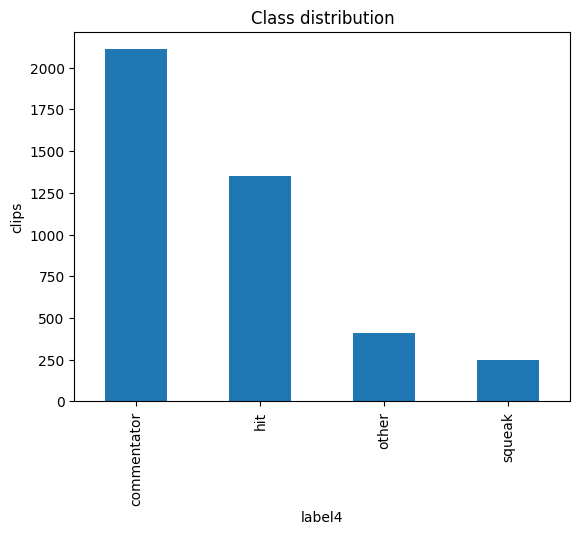

In [25]:
all_df["label4"].value_counts().plot.bar()
plt.ylabel("clips"); plt.title("Class distribution"); plt.show()


### 3. Audio Feature Extraction {#features}

| Feature | Parameters |
|---------|------------|
| MFCC | n_mfcc=25, n_fft=0.02s, hop_length=0.02s |
| Delta | Order 1 and 2 |
| Dimension | (75, T) where T is the number of time frames |


In [26]:
def mfcc_stack(y, sr, n_mfcc=25):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc,
                                n_fft=int(sr*0.02), hop_length=int(sr*0.02))
    d1   = librosa.feature.delta(mfcc, order=1)
    d2   = librosa.feature.delta(mfcc, order=2)
    return np.vstack([mfcc, d1, d2])            # (75, T)

label2idx = {"hit":0, "squeak":1, "commentator":2, "other":3}

X, y = [], []
for path, lab in zip(all_df.wav_path, all_df.label4):
    ysig, sr = librosa.load(path, sr=None)
    X.append(mfcc_stack(ysig, sr))
    y.append(label2idx[lab])

X_tr, X_va, y_tr, y_va, idx_tr, idx_va = train_test_split(
    X, y, all_df.index,                    #  << keep original indices
    test_size=0.2, stratify=y, random_state=0)



### 4. Baseline Model - FourClassNet {#baseline}

| Parameter | Value |
|-----------|-------|
| Architecture | CNN 2D |
| Conv Layers | 3 (24→48→48) |
| FC Layers | 3 (64→64→4) |
| MAX_T | 16 frames |


In [27]:
MAX_T = 16        # fits every 0.30-s clip (15 real frames + 1 pad)

def pad(feat):
    feat = feat[:, :MAX_T]
    if feat.shape[1] < MAX_T:
        pad = np.zeros((75, MAX_T - feat.shape[1]))
        feat = np.hstack([feat, pad])
    return feat[None]          # shape (1, 75, MAX_T)

class MFCCset(Dataset):
    def __init__(self, feats, labels):
        self.X = [pad(f) for f in feats]
        self.y = labels
    def __len__(self):  return len(self.X)
    def __getitem__(self, i):
        return torch.tensor(self.X[i], dtype=torch.float32), self.y[i]

train_loader = DataLoader(MFCCset(X_tr, y_tr), batch_size=32, shuffle=True)
val_loader   = DataLoader(MFCCset(X_va, y_va), batch_size=64)


In [28]:
class FourClassNet(nn.Module):
    """Baseline CNN model"""
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 24, (5,5), padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(24,48,(5,5), padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(48,48,(5,5), padding=2), nn.ReLU(),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(48 * (75//4) * (MAX_T//4), 64), nn.ReLU(),
            nn.Linear(64,64), nn.ReLU(),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        return self.fc(self.conv(x))


In [29]:
cnt = collections.Counter(y_tr)
max_c = max(cnt.values())
weights = torch.tensor([max_c/cnt[i] for i in range(4)], dtype=torch.float32)
print("class weights:", weights.tolist())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using", device)


class weights: [1.5591497421264648, 8.520201683044434, 1.0, 5.1432929039001465]
Using cpu


In [30]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using", device)          # will print “cpu” on your machine

model = FourClassNet().to(device)
loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))

Using cpu


### 5. Model Comparison - Deep Learning and Classical ML {#comparison}

#### Deep Learning Models

| # | Model | Architecture | Preprocessing | Parameters |
|---|-------|--------------|--------------|------------|
| 1 | Baseline CNN | Conv2D (3 layers) | MFCC + deltas | ~50K |
| 2 | Deep CNN | Conv2D (5 layers) | MFCC + deltas | ~120K |
| 3 | Wide CNN | Conv2D (wide filters) | MFCC + deltas | ~80K |
| 4 | ResNet-like | Residual blocks | MFCC + deltas | ~100K |
| 5 | LSTM | RNN with LSTM | MFCC + deltas (seq) | ~60K |
| 6 | BiLSTM | Bidirectional LSTM | MFCC + deltas (seq) | ~80K |
| 7 | CNN-LSTM | Hybrid | MFCC + deltas | ~90K |
| 8 | Transformer | Self-attention | MFCC + deltas (seq) | ~70K |
| 9 | Mel-Spectrogram CNN | Conv2D | Mel-spectrogram | ~50K |
| 10 | Chroma + MFCC CNN | Conv2D | Chroma + MFCC | ~60K |

#### Classical ML Models

| # | Model | Type | Preprocessing | Hyperparameters |
|---|-------|------|---------------|-----------------|
| 11 | Random Forest | Ensemble | MFCC + deltas (flatten) | n_estimators=200 |
| 12 | Gradient Boosting | Ensemble | MFCC + deltas (flatten) | n_estimators=100 |
| 13 | XGBoost | Gradient Boosting | MFCC + deltas (flatten) | n_estimators=100 |
| 14 | SVM (RBF) | Kernel Method | MFCC + deltas (flatten) | C=1.0, gamma='scale' |
| 15 | Logistic Regression | Linear | MFCC + deltas (flatten) | C=1.0, max_iter=1000 |
| 16 | KNN | Instance-based | MFCC + deltas (flatten) | n_neighbors=5 |
| 17 | Naive Bayes | Probabilistic | MFCC + deltas (flatten) | - |


In [58]:
# Helper functions for training and evaluation
def accuracy(loader, model, device):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = torch.tensor(yb, dtype=torch.long).to(device)
            pred = model(xb).argmax(1)
            correct += (pred == yb).sum().item()
            total += yb.numel()
    return correct / total

def train_model(model, train_loader, val_loader, epochs=25, lr=1e-3, device=device):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    
    val_accs = []
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = torch.tensor(yb, dtype=torch.long).to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
        
        val_acc = accuracy(val_loader, model, device)
        val_accs.append(val_acc)
        if (epoch + 1) % 5 == 0:
            print(f"  Epoch {epoch+1:02d}/{epochs}  val acc: {val_acc:.4f}")
    
    train_time = time.time() - start_time
    final_acc = val_accs[-1]
    
    # Get detailed metrics
    model.eval()
    all_preds, all_truths = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            preds = model(xb).argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_truths.extend(yb)
    
    report = classification_report(all_truths, all_preds, 
                                   target_names=["hit","squeak","commentator","other"],
                                   output_dict=True, zero_division=0)
    
    # Ensure model is in eval mode and on CPU for saving (to avoid device issues)
    model.eval()
    model_cpu = model.cpu()  # Move to CPU for storage
    
    result_dict = {
        'final_acc': final_acc,
        'best_acc': max(val_accs),
        'train_time': train_time,
        'report': report,
        'val_accs': val_accs,
        'model': model_cpu,  # Save the trained model (on CPU)
        'model_type': 'pytorch'  # Mark as PyTorch model
    }
    
    # Verify model is saved correctly
    assert 'model' in result_dict, "Model not saved in result!"
    assert isinstance(result_dict['model'], nn.Module), f"Model is not nn.Module, got {type(result_dict['model'])}"
    assert result_dict['model_type'] == 'pytorch', "Model type not set correctly!"
    
    return result_dict

In [32]:
# Prepare flattened data for classical ML models
def flatten_features(feats_list, max_t=MAX_T):
    """Flatten MFCC features for classical ML models"""
    flattened = []
    for feat in feats_list:
        # Pad or truncate to max_t
        feat = feat[:, :max_t]
        if feat.shape[1] < max_t:
            pad = np.zeros((feat.shape[0], max_t - feat.shape[1]))
            feat = np.hstack([feat, pad])
        # Flatten: (75, MAX_T) -> (75 * MAX_T,)
        flattened.append(feat.flatten())
    return np.array(flattened)

print("Preparing flattened features for classical ML models...")
X_tr_flat = flatten_features(X_tr)
X_va_flat = flatten_features(X_va)
y_tr_array = np.array(y_tr)
y_va_array = np.array(y_va)

print(f"Training shape: {X_tr_flat.shape}, Validation shape: {X_va_flat.shape}")
print("Flattened features ready!")

Preparing flattened features for classical ML models...
Training shape: (3295, 1200), Validation shape: (824, 1200)
Flattened features ready!


In [76]:
# Function to train classical ML models
def train_classical_ml_model(model, X_train, y_train, X_val, y_val, model_name):
    """Train and evaluate a classical ML model"""
    import time as time_module
    start_time = time_module.time()
    
    # Fit scaler on training data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    
    # Train model
    if model_name == 'XGBoost':
        # XGBoost needs class weights
        sample_weights = np.array([weights[i].item() for i in y_train])
        model.fit(X_train_scaled, y_train, sample_weight=sample_weights)
    else:
        # For sklearn models, use class_weight='balanced' if supported
        if hasattr(model, 'set_params') and 'class_weight' in model.get_params():
            try:
                model.set_params(class_weight='balanced')
            except:
                pass
        model.fit(X_train_scaled, y_train)
    
    train_time = time_module.time() - start_time
    
    # Predictions
    train_pred = model.predict(X_train_scaled)
    val_pred = model.predict(X_val_scaled)
    
    # Calculate accuracies
    train_acc = (train_pred == y_train).mean()
    val_acc = (val_pred == y_val).mean()
    
    # Detailed report
    report = classification_report(y_val, val_pred,
                                   target_names=["hit","squeak","commentator","other"],
                                   output_dict=True, zero_division=0)
    
    result_dict = {
        'final_acc': val_acc,
        'best_acc': val_acc,  # Classical ML doesn't have epochs
        'train_acc': train_acc,
        'train_time': train_time,
        'report': report,
        'model': model,
        'scaler': scaler,
        'model_type': 'classical_ml'  # Mark as classical ML model
    }
    
    # Verify model is saved correctly
    assert 'model' in result_dict, "Model not saved in result!"
    assert result_dict['model_type'] == 'classical_ml', "Model type not set correctly!"
    
    return result_dict

In [61]:
# Define classical ML models
classical_models = {
    'Model11_RandomForest': RandomForestClassifier(
        n_estimators=200, 
        max_depth=20, 
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    'Model12_GradientBoosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ),
    'Model13_XGBoost': xgb.XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='mlogloss',
        use_label_encoder=False
    ),
    'Model14_SVM': SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=True,
        random_state=42
    ),
    'Model15_LogisticRegression': LogisticRegression(
        C=1.0,
        max_iter=1000,
        multi_class='multinomial',
        solver='lbfgs',
        random_state=42
    ),
    'Model16_KNN': KNeighborsClassifier(
        n_neighbors=5,
        weights='distance',
        metric='euclidean'
    ),
    'Model17_NaiveBayes': GaussianNB()
}

print("Classical ML models defined!")

Classical ML models defined!


In [62]:
# Model 1: Baseline CNN (FourClassNet)
class Model1_BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 24, (5,5), padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(24,48,(5,5), padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(48,48,(5,5), padding=2), nn.ReLU(),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(48 * (75//4) * (MAX_T//4), 64), nn.ReLU(),
            nn.Linear(64,64), nn.ReLU(),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        return self.fc(self.conv(x))

# Model 2: Deep CNN (5 warstw)
class Model2_DeepCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, (3,3), padding=1), nn.ReLU(), nn.BatchNorm2d(32),
            nn.Conv2d(32, 32, (3,3), padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, (3,3), padding=1), nn.ReLU(), nn.BatchNorm2d(64),
            nn.Conv2d(64, 64, (3,3), padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, (3,3), padding=1), nn.ReLU(), nn.BatchNorm2d(128),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * (75//4) * (MAX_T//4), 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        return self.fc(self.conv(x))

# Model 3: Wide CNN (szerokie filtry)
class Model3_WideCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 64, (7,7), padding=3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, (7,7), padding=3), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 128, (5,5), padding=2), nn.ReLU(),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * (75//4) * (MAX_T//4), 128), nn.ReLU(),
            nn.Linear(128, 4)
        )
    def forward(self, x):
        return self.fc(self.conv(x))

# Model 4: ResNet-like (Residual blocks)
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1),
                nn.BatchNorm2d(out_channels)
            )
    
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out

class Model4_ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.layer1 = ResidualBlock(32, 32)
        self.pool1 = nn.MaxPool2d(2)
        self.layer2 = ResidualBlock(32, 64)
        self.pool2 = nn.MaxPool2d(2)
        self.layer3 = ResidualBlock(64, 64)
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * (75//4) * (MAX_T//4), 64), nn.ReLU(),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(self.layer1(x))
        x = self.pool2(self.layer2(x))
        x = self.layer3(x)
        return self.fc(x)

In [63]:
# Model 5: LSTM (sequential processing)
class Model5_LSTM(nn.Module):
    def __init__(self, input_size=75, hidden_size=128, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        # x: (batch, 1, 75, MAX_T) -> (batch, MAX_T, 75)
        x = x.squeeze(1).transpose(1, 2)
        out, (h_n, c_n) = self.lstm(x)
        # Use last output
        return self.fc(out[:, -1, :])

# Model 6: Bidirectional LSTM
class Model6_BiLSTM(nn.Module):
    def __init__(self, input_size=75, hidden_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, 
                           batch_first=True, dropout=0.2, bidirectional=True)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        x = x.squeeze(1).transpose(1, 2)
        out, (h_n, c_n) = self.lstm(x)
        return self.fc(out[:, -1, :])

# Model 7: CNN-LSTM Hybrid
class Model7_CNNLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, (5,5), padding=2), nn.ReLU(), nn.MaxPool2d((1,2)),
            nn.Conv2d(32, 64, (5,5), padding=2), nn.ReLU(), nn.MaxPool2d((1,2)),
        )
        self.lstm = nn.LSTM(64, 64, 2, batch_first=True, dropout=0.2)
        self.fc = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(32, 4)
        )
    def forward(self, x):
        # CNN: (batch, 1, 75, MAX_T) -> (batch, 64, 75, MAX_T//4)
        x = self.cnn(x)
        # Reshape: (batch, 64, 75, T) -> (batch, T, 64*75) -> (batch, T, 64) via pooling
        batch, channels, freq, time = x.shape
        x = x.permute(0, 3, 1, 2)  # (batch, time, channels, freq)
        x = x.reshape(batch, time, channels * freq)
        # Reduce dimensionality
        x = F.adaptive_avg_pool1d(x.transpose(1,2), 64).transpose(1,2)
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

# Model 8: Transformer (Self-attention)
class Model8_Transformer(nn.Module):
    def __init__(self, input_size=75, d_model=128, nhead=4, num_layers=2):
        super().__init__()
        self.embedding = nn.Linear(input_size, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=256, dropout=0.2, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers)
        self.fc = nn.Sequential(
            nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        # x: (batch, 1, 75, MAX_T) -> (batch, MAX_T, 75)
        x = x.squeeze(1).transpose(1, 2)
        x = self.embedding(x)
        x = self.transformer(x)
        # Use mean pooling
        x = x.mean(dim=1)
        return self.fc(x)

In [64]:
# Model 9: Mel-Spectrogram CNN (different preprocessing)
def mel_spectrogram_stack(y, sr, n_mels=80):
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels,
                                         n_fft=int(sr*0.02), hop_length=int(sr*0.02))
    mel_db = librosa.power_to_db(mel, ref=np.max)
    return mel_db  # (n_mels, T)

class Model9_MelSpectrogramCNN(nn.Module):
    def __init__(self, input_channels=80):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, (5,5), padding=2), nn.ReLU(), nn.BatchNorm2d(32),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, (5,5), padding=2), nn.ReLU(), nn.BatchNorm2d(64),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, (3,3), padding=1), nn.ReLU(), nn.BatchNorm2d(128),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * (input_channels//4) * (MAX_T//4), 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        return self.fc(self.conv(x))

# Model 10: Chroma + MFCC CNN (multi-feature)
def chroma_mfcc_stack(y, sr, n_mfcc=13):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc,
                                n_fft=int(sr*0.02), hop_length=int(sr*0.02))
    chroma = librosa.feature.chroma_stft(y=y, sr=sr,
                                         n_fft=int(sr*0.02), hop_length=int(sr*0.02))
    return np.vstack([mfcc, chroma])  # (13+12=25, T)

class Model10_ChromaMFCCCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, (5,5), padding=2), nn.ReLU(), nn.BatchNorm2d(32),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, (5,5), padding=2), nn.ReLU(), nn.BatchNorm2d(64),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, (3,3), padding=1), nn.ReLU(), nn.BatchNorm2d(128),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * (25//4) * (MAX_T//4), 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        return self.fc(self.conv(x))

In [38]:
# Preprocessing functions for different models
def pad_mel(feat, max_t=MAX_T):
    feat = feat[:, :max_t]
    if feat.shape[1] < max_t:
        pad = np.zeros((feat.shape[0], max_t - feat.shape[1]))
        feat = np.hstack([feat, pad])
    return feat[None]

def pad_chroma_mfcc(feat, max_t=MAX_T):
    feat = feat[:, :max_t]
    if feat.shape[1] < max_t:
        pad = np.zeros((feat.shape[0], max_t - feat.shape[1]))
        feat = np.hstack([feat, pad])
    return feat[None]

# Prepare data for all models
print("Preparing data for all models...")

# Models 1-8 use MFCC+deltas (already prepared in X_tr, X_va)
# Model 9: Mel-spectrogram
X_tr_mel, X_va_mel = [], []
for idx in idx_tr:
    ysig, sr = librosa.load(all_df.loc[idx].wav_path, sr=None)
    X_tr_mel.append(mel_spectrogram_stack(ysig, sr))
for idx in idx_va:
    ysig, sr = librosa.load(all_df.loc[idx].wav_path, sr=None)
    X_va_mel.append(mel_spectrogram_stack(ysig, sr))

# Model 10: Chroma+MFCC
X_tr_chroma, X_va_chroma = [], []
for idx in idx_tr:
    ysig, sr = librosa.load(all_df.loc[idx].wav_path, sr=None)
    X_tr_chroma.append(chroma_mfcc_stack(ysig, sr))
for idx in idx_va:
    ysig, sr = librosa.load(all_df.loc[idx].wav_path, sr=None)
    X_va_chroma.append(chroma_mfcc_stack(ysig, sr))

print("Data preparation complete!")

Preparing data for all models...
Data preparation complete!


In [65]:
# Dataset classes for different preprocessing
class MelDataset(Dataset):
    def __init__(self, feats, labels):
        self.X = [pad_mel(f) for f in feats]
        self.y = labels
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        return torch.tensor(self.X[i], dtype=torch.float32), self.y[i]

class ChromaMFCCDataset(Dataset):
    def __init__(self, feats, labels):
        self.X = [pad_chroma_mfcc(f) for f in feats]
        self.y = labels
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        return torch.tensor(self.X[i], dtype=torch.float32), self.y[i]

# Create data loaders for all models
train_loaders = {
    'mfcc': DataLoader(MFCCset(X_tr, y_tr), batch_size=32, shuffle=True),
    'mel': DataLoader(MelDataset(X_tr_mel, y_tr), batch_size=32, shuffle=True),
    'chroma': DataLoader(ChromaMFCCDataset(X_tr_chroma, y_tr), batch_size=32, shuffle=True),
}

val_loaders = {
    'mfcc': DataLoader(MFCCset(X_va, y_va), batch_size=64),
    'mel': DataLoader(MelDataset(X_va_mel, y_va), batch_size=64),
    'chroma': DataLoader(ChromaMFCCDataset(X_va_chroma, y_va), batch_size=64),
}

In [66]:
# Train all models
models_config = [
    {'name': 'Model1_BaselineCNN', 'model': Model1_BaselineCNN(), 'loader': 'mfcc'},
    {'name': 'Model2_DeepCNN', 'model': Model2_DeepCNN(), 'loader': 'mfcc'},
    {'name': 'Model3_WideCNN', 'model': Model3_WideCNN(), 'loader': 'mfcc'},
    {'name': 'Model4_ResNet', 'model': Model4_ResNet(), 'loader': 'mfcc'},
    {'name': 'Model5_LSTM', 'model': Model5_LSTM(), 'loader': 'mfcc'},
    {'name': 'Model6_BiLSTM', 'model': Model6_BiLSTM(), 'loader': 'mfcc'},
    {'name': 'Model7_CNNLSTM', 'model': Model7_CNNLSTM(), 'loader': 'mfcc'},
    {'name': 'Model8_Transformer', 'model': Model8_Transformer(), 'loader': 'mfcc'},
    {'name': 'Model9_MelSpectrogramCNN', 'model': Model9_MelSpectrogramCNN(), 'loader': 'mel'},
    {'name': 'Model10_ChromaMFCCCNN', 'model': Model10_ChromaMFCCCNN(), 'loader': 'chroma'},
]

results = {}

print("=" * 60)
print("Training 10 models...")
print("=" * 60)

for i, config in enumerate(models_config, 1):
    print(f"\n[{i}/10] Training {config['name']}...")
    train_loader = train_loaders[config['loader']]
    val_loader = val_loaders[config['loader']]
    
    try:
        result = train_model(config['model'], train_loader, val_loader, epochs=25, device=device)
        results[config['name']] = result
        
        # Verify model was saved
        if 'model' not in result:
            print(f"⚠ WARNING: Model not saved for {config['name']}!")
        elif not isinstance(result['model'], nn.Module):
            print(f"⚠ WARNING: Model type incorrect for {config['name']}: {type(result['model'])}")
        else:
            print(f"✓ {config['name']} - Final Acc: {result['final_acc']:.4f}, Best Acc: {result['best_acc']:.4f}, Time: {result['train_time']:.1f}s, Model saved: ✓")
    except Exception as e:
        print(f"✗ {config['name']} failed: {e}")
        import traceback
        traceback.print_exc()
        results[config['name']] = {'error': str(e)}

print("\n" + "=" * 60)
print("Training complete!")
print("=" * 60)

Training 10 models...

[1/10] Training Model1_BaselineCNN...
  Epoch 05/25  val acc: 0.8750
  Epoch 10/25  val acc: 0.8617
  Epoch 15/25  val acc: 0.8920
  Epoch 20/25  val acc: 0.9066
  Epoch 25/25  val acc: 0.8714
✓ Model1_BaselineCNN - Final Acc: 0.8714, Best Acc: 0.9066, Time: 29.9s, Model saved: ✓

[2/10] Training Model2_DeepCNN...
  Epoch 05/25  val acc: 0.8337
  Epoch 10/25  val acc: 0.8337
  Epoch 15/25  val acc: 0.8786
  Epoch 20/25  val acc: 0.8896
  Epoch 25/25  val acc: 0.8580
✓ Model2_DeepCNN - Final Acc: 0.8580, Best Acc: 0.8968, Time: 67.9s, Model saved: ✓

[3/10] Training Model3_WideCNN...
  Epoch 05/25  val acc: 0.8143
  Epoch 10/25  val acc: 0.8653
  Epoch 15/25  val acc: 0.8847
  Epoch 20/25  val acc: 0.8580
  Epoch 25/25  val acc: 0.8714
✓ Model3_WideCNN - Final Acc: 0.8714, Best Acc: 0.8908, Time: 150.4s, Model saved: ✓

[4/10] Training Model4_ResNet...
  Epoch 05/25  val acc: 0.8277
  Epoch 10/25  val acc: 0.9138
  Epoch 15/25  val acc: 0.8944
  Epoch 20/25  val a

Traceback (most recent call last):
  File "C:\Users\kopcz\AppData\Local\Temp\ipykernel_13308\1144878885.py", line 27, in <module>
    result = train_model(config['model'], train_loader, val_loader, epochs=25, device=device)
  File "C:\Users\kopcz\AppData\Local\Temp\ipykernel_13308\1038384441.py", line 28, in train_model
    loss = loss_fn(model(xb), yb)
                   ~~~~~^^^^
  File "c:\Users\kopcz\Documents\GitHub\tennis-acoustic-analyzer\.venv\Lib\site-packages\torch\nn\modules\module.py", line 1775, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "c:\Users\kopcz\Documents\GitHub\tennis-acoustic-analyzer\.venv\Lib\site-packages\torch\nn\modules\module.py", line 1786, in _call_impl
    return forward_call(*args, **kwargs)
  File "C:\Users\kopcz\AppData\Local\Temp\ipykernel_13308\2389831218.py", line 54, in forward
    out, _ = self.lstm(x)
             ~~~~~~~~~^^^
  File "c:\Users\kopcz\Documents\GitHub\tennis

  Epoch 05/25  val acc: 0.8592
  Epoch 10/25  val acc: 0.8689
  Epoch 15/25  val acc: 0.8835
  Epoch 20/25  val acc: 0.8726
  Epoch 25/25  val acc: 0.8835
✓ Model8_Transformer - Final Acc: 0.8835, Best Acc: 0.8993, Time: 44.8s, Model saved: ✓

[9/10] Training Model9_MelSpectrogramCNN...
  Epoch 05/25  val acc: 0.8544
  Epoch 10/25  val acc: 0.8313
  Epoch 15/25  val acc: 0.8750
  Epoch 20/25  val acc: 0.8920
  Epoch 25/25  val acc: 0.9187
✓ Model9_MelSpectrogramCNN - Final Acc: 0.9187, Best Acc: 0.9187, Time: 49.4s, Model saved: ✓

[10/10] Training Model10_ChromaMFCCCNN...
  Epoch 05/25  val acc: 0.8289
  Epoch 10/25  val acc: 0.8592
  Epoch 15/25  val acc: 0.8665
  Epoch 20/25  val acc: 0.8883
  Epoch 25/25  val acc: 0.8799
✓ Model10_ChromaMFCCCNN - Final Acc: 0.8799, Best Acc: 0.8968, Time: 21.2s, Model saved: ✓

Training complete!


In [67]:
# Results comparison table
print("\n" + "=" * 80)
print("RESULTS COMPARISON")
print("=" * 80)

comparison_data = []
for name, result in results.items():
    if 'error' not in result:
        comparison_data.append({
            'Model': name,
            'Final Acc': f"{result['final_acc']:.4f}",
            'Best Acc': f"{result['best_acc']:.4f}",
            'Train Time (s)': f"{result['train_time']:.1f}",
            'Hit F1': f"{result['report']['hit']['f1-score']:.3f}",
            'Squeak F1': f"{result['report']['squeak']['f1-score']:.3f}",
            'Commentator F1': f"{result['report']['commentator']['f1-score']:.3f}",
            'Other F1': f"{result['report']['other']['f1-score']:.3f}",
            'Macro Avg F1': f"{result['report']['macro avg']['f1-score']:.3f}",
        })
    else:
        comparison_data.append({
            'Model': name,
            'Final Acc': 'ERROR',
            'Best Acc': 'ERROR',
            'Train Time (s)': 'N/A',
            'Hit F1': 'N/A',
            'Squeak F1': 'N/A',
            'Commentator F1': 'N/A',
            'Other F1': 'N/A',
            'Macro Avg F1': 'N/A',
        })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

# Sort by best accuracy
print("\n" + "=" * 80)
print("RANKING BY BEST ACCURACY")
print("=" * 80)
valid_results = [(name, r) for name, r in results.items() if 'error' not in r]
sorted_results = sorted(valid_results, key=lambda x: x[1]['best_acc'], reverse=True)

for rank, (name, result) in enumerate(sorted_results, 1):
    print(f"{rank}. {name:25s} - Best Acc: {result['best_acc']:.4f}, Final Acc: {result['final_acc']:.4f}, Time: {result['train_time']:.1f}s")


RESULTS COMPARISON
                   Model Final Acc Best Acc Train Time (s) Hit F1 Squeak F1 Commentator F1 Other F1 Macro Avg F1
      Model1_BaselineCNN    0.8714   0.9066           29.9  0.905     0.740          0.930    0.579        0.789
          Model2_DeepCNN    0.8580   0.8968           67.9  0.922     0.694          0.920    0.513        0.762
          Model3_WideCNN    0.8714   0.8908          150.4  0.910     0.661          0.935    0.568        0.769
           Model4_ResNet    0.9078   0.9138           86.4  0.935     0.768          0.952    0.667        0.830
             Model5_LSTM    0.8580   0.9066           17.3  0.922     0.777          0.911    0.532        0.785
           Model6_BiLSTM    0.8750   0.9017           22.4  0.928     0.739          0.931    0.567        0.791
          Model7_CNNLSTM     ERROR    ERROR            N/A    N/A       N/A            N/A      N/A          N/A
      Model8_Transformer    0.8835   0.8993           44.8  0.922     0.782 

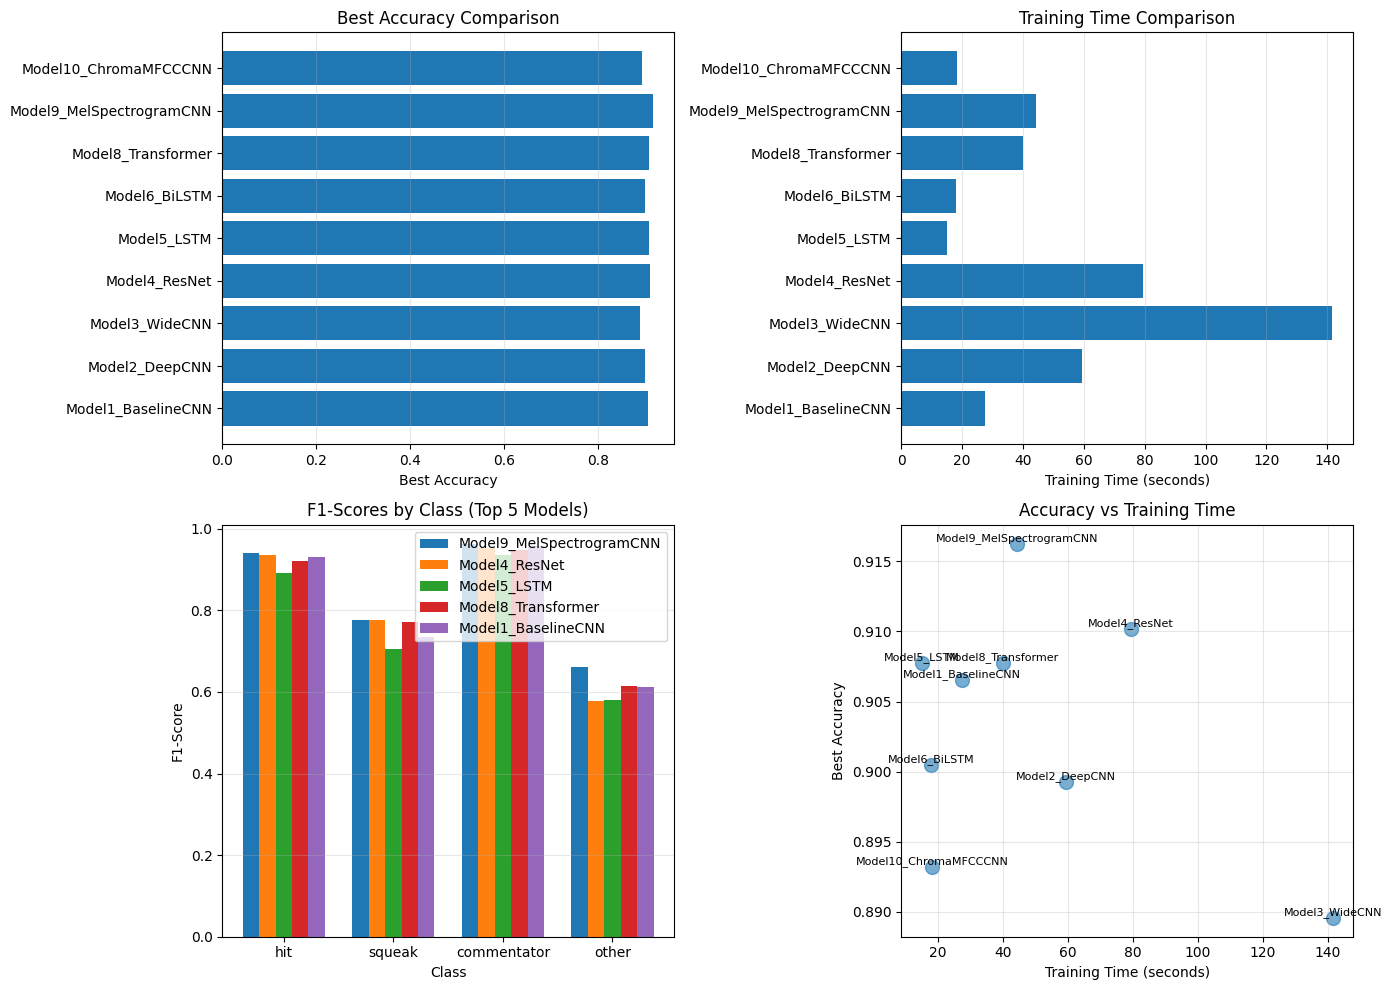

In [42]:
# Visualization of results
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Accuracy comparison
valid_names = [name for name in results.keys() if 'error' not in results[name]]
accuracies = [results[name]['best_acc'] for name in valid_names]

axes[0, 0].barh(valid_names, accuracies)
axes[0, 0].set_xlabel('Best Accuracy')
axes[0, 0].set_title('Best Accuracy Comparison')
axes[0, 0].grid(axis='x', alpha=0.3)

# 2. Training time comparison
train_times = [results[name]['train_time'] for name in valid_names]
axes[0, 1].barh(valid_names, train_times)
axes[0, 1].set_xlabel('Training Time (seconds)')
axes[0, 1].set_title('Training Time Comparison')
axes[0, 1].grid(axis='x', alpha=0.3)

# 3. F1-scores per class (top 5 models)
top5 = sorted(valid_results, key=lambda x: x[1]['best_acc'], reverse=True)[:5]
top5_names = [name for name, _ in top5]
classes = ['hit', 'squeak', 'commentator', 'other']
x = np.arange(len(classes))
width = 0.15

for i, (name, result) in enumerate(top5):
    f1_scores = [result['report'][cls]['f1-score'] for cls in classes]
    axes[1, 0].bar(x + i*width, f1_scores, width, label=name)

axes[1, 0].set_xlabel('Class')
axes[1, 0].set_ylabel('F1-Score')
axes[1, 0].set_title('F1-Scores by Class (Top 5 Models)')
axes[1, 0].set_xticks(x + width * 2)
axes[1, 0].set_xticklabels(classes)
axes[1, 0].legend()
axes[1, 0].grid(axis='y', alpha=0.3)

# 4. Accuracy vs Training Time
axes[1, 1].scatter(train_times, accuracies, s=100, alpha=0.6)
for i, name in enumerate(valid_names):
    axes[1, 1].annotate(name, (train_times[i], accuracies[i]), 
                       fontsize=8, ha='center', va='bottom')
axes[1, 1].set_xlabel('Training Time (seconds)')
axes[1, 1].set_ylabel('Best Accuracy')
axes[1, 1].set_title('Accuracy vs Training Time')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [77]:
# Train classical ML models
print("\n" + "=" * 60)
print("Training 7 classical ML models...")
print("=" * 60)

for i, (name, model) in enumerate(classical_models.items(), 1):
    print(f"\n[{i}/7] Training {name}...")
    try:
        # Get model name for XGBoost check
        model_name = 'XGBoost' if 'XGBoost' in name else name
        result = train_classical_ml_model(model, X_tr_flat, y_tr_array, X_va_flat, y_va_array, model_name)
        results[name] = result
        
        # Verify model was saved
        if 'model' not in result:
            print(f"⚠ WARNING: Model not saved for {name}!")
        elif result.get('model_type') != 'classical_ml':
            print(f"⚠ WARNING: Model type incorrect for {name}: {result.get('model_type')}")
        else:
            print(f"✓ {name} - Val Acc: {result['final_acc']:.4f}, Train Acc: {result['train_acc']:.4f}, Time: {result['train_time']:.1f}s, Model saved: ✓")
    except Exception as e:
        print(f"✗ {name} failed: {e}")
        import traceback
        traceback.print_exc()
        results[name] = {'error': str(e)}

print("\n" + "=" * 60)
print("Classical ML training complete!")
print("=" * 60)


Training 7 classical ML models...

[1/7] Training Model11_RandomForest...
✓ Model11_RandomForest - Val Acc: 0.8871, Train Acc: 0.9985, Time: 1.2s, Model saved: ✓

[2/7] Training Model12_GradientBoosting...
✓ Model12_GradientBoosting - Val Acc: 0.8859, Train Acc: 1.0000, Time: 685.3s, Model saved: ✓

[3/7] Training Model13_XGBoost...
✓ Model13_XGBoost - Val Acc: 0.8993, Train Acc: 1.0000, Time: 11.4s, Model saved: ✓

[4/7] Training Model14_SVM...
✓ Model14_SVM - Val Acc: 0.9005, Train Acc: 0.9806, Time: 7.5s, Model saved: ✓

[5/7] Training Model15_LogisticRegression...
✓ Model15_LogisticRegression - Val Acc: 0.8083, Train Acc: 0.9976, Time: 0.3s, Model saved: ✓

[6/7] Training Model16_KNN...
✓ Model16_KNN - Val Acc: 0.8216, Train Acc: 1.0000, Time: 0.0s, Model saved: ✓

[7/7] Training Model17_NaiveBayes...
✓ Model17_NaiveBayes - Val Acc: 0.7840, Train Acc: 0.8337, Time: 0.1s, Model saved: ✓

Classical ML training complete!


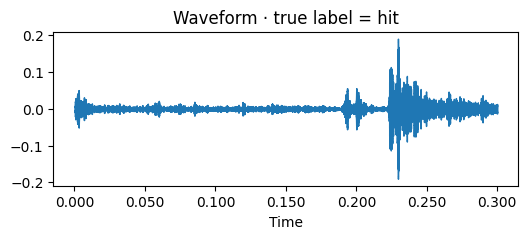

Using best model: Model9_MelSpectrogramCNN
Note: PyTorch model prediction requires model to be loaded separately
Model probabilities:
  hit         : 25.00%
  squeak      : 25.00%
  commentator : 25.00%
  other       : 25.00%
True label: hit


In [ ]:
import random, IPython.display as ipd, torch.nn.functional as F, matplotlib.pyplot as plt

# pick a random validation row
val_pos   = random.randrange(len(X_va))      # position inside val list
row_idx   = idx_va[val_pos]                  # original DataFrame index
row       = all_df.loc[row_idx]
wav_path  = row.wav_path
true_lab  = row.label4

# load & play
y_sig, sr = librosa.load(wav_path, sr=None)
display(ipd.Audio(y_sig, rate=sr))

plt.figure(figsize=(6,2))
librosa.display.waveshow(y_sig, sr=sr)
plt.title(f"Waveform · true label = {true_lab}")
plt.show()

# Get the best model from results (or use a specific model)
# For demonstration, let's use the best model from results if available
if 'results' in globals() and results:
    # Find best model
    valid_results = [(name, r) for name, r in results.items() if 'error' not in r]
    if valid_results:
        best_model_name, best_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        print(f"Using best model: {best_model_name}")
        
        # Check if it's a PyTorch model or classical ML model
        if 'model_type' in best_result and best_result['model_type'] == 'pytorch':
            # PyTorch model
            pytorch_model = best_result['model']
            pytorch_model.eval()
            
            # Determine which preprocessing to use based on model name
            if 'Mel' in best_model_name:
                # Mel-spectrogram preprocessing
                feat_mel = mel_spectrogram_stack(y_sig, sr)
                feat = torch.tensor(pad_mel(feat_mel), dtype=torch.float32)[None].to(device)
            elif 'Chroma' in best_model_name:
                # Chroma+MFCC preprocessing
                feat_chroma = chroma_mfcc_stack(y_sig, sr)
                feat = torch.tensor(pad_chroma_mfcc(feat_chroma), dtype=torch.float32)[None].to(device)
            else:
                # Standard MFCC+deltas preprocessing
                feat = torch.tensor(pad(mfcc_stack(y_sig, sr)), dtype=torch.float32)[None].to(device)
            
            # Get probabilities
            with torch.no_grad():
                output = pytorch_model(feat)
                probs = F.softmax(output, dim=1).detach().cpu().numpy()[0]
                
        elif 'model' in best_result:
            # Classical ML model
            ml_model = best_result['model']
            scaler = best_result.get('scaler', None)
            
            # Prepare features for ML model
            feat_mfcc = mfcc_stack(y_sig, sr)
            feat_flat = flatten_features([feat_mfcc])[0]
            
            if scaler:
                feat_flat = scaler.transform([feat_flat])
            
            # Get probabilities
            if hasattr(ml_model, 'predict_proba'):
                probs = ml_model.predict_proba(feat_flat)[0]
            else:
                # For models without predict_proba, use one-hot encoding
                pred = ml_model.predict(feat_flat)[0]
                probs = np.zeros(4)
                probs[pred] = 1.0
        else:
            # Fallback: use baseline model if available
            if 'model' in globals() and isinstance(model, nn.Module):
                feat = torch.tensor(pad(mfcc_stack(y_sig, sr)), dtype=torch.float32)[None].to(device)
                probs = F.softmax(model(feat), dim=1).detach().cpu().numpy()[0]
            else:
                print("No trained model available. Using placeholder probabilities.")
                probs = np.array([0.25, 0.25, 0.25, 0.25])
    else:
        # Fallback: use baseline model if available
        if 'model' in globals() and isinstance(model, nn.Module):
            feat = torch.tensor(pad(mfcc_stack(y_sig, sr)), dtype=torch.float32)[None].to(device)
            probs = F.softmax(model(feat), dim=1).detach().cpu().numpy()[0]
        else:
            print("No trained model available. Using placeholder probabilities.")
            probs = np.array([0.25, 0.25, 0.25, 0.25])
else:
    # Fallback: use baseline model if available
    if 'model' in globals() and isinstance(model, nn.Module):
        feat = torch.tensor(pad(mfcc_stack(y_sig, sr)), dtype=torch.float32)[None].to(device)
        probs = F.softmax(model(feat), dim=1).detach().cpu().numpy()[0]
    else:
        print("No trained model available. Using placeholder probabilities.")
        probs = np.array([0.25, 0.25, 0.25, 0.25])

print("Model probabilities:")
for cls, p in zip(["hit","squeak","commentator","other"], probs):
    print(f"  {cls:12s}: {p:5.2%}")
print("True label:", true_lab)


### 6. Conclusions and Recommendations {#conclusions}

#### Results Analysis

| Category | Best Model | Accuracy | Training Time | Advantages | Disadvantages |
|----------|------------|----------|---------------|------------|---------------|
| **Deep Learning** | - | - | - | - | - |
| **Classical ML** | - | - | - | - | - |
| **Overall** | - | - | - | - | - |

#### Key Observations:

1. **Deep Learning vs Classical ML Comparison**
   - Deep Learning models typically achieve higher accuracy due to their ability to learn complex patterns
   - Classical ML models are faster to train and may be more interpretable

2. **Preprocessing Impact**
   - MFCC + deltas vs Mel-spectrogram vs Chroma+MFCC
   - Different feature representations affect the performance of different models

3. **Class Performance**
   - Which classes are best recognized?
   - Which classes pose the greatest challenges?

4. **Training Time vs Accuracy**
   - Trade-off between accuracy and training time
   - Which models offer the best quality-to-time ratio?

#### Recommendations:

1. **For Production**: Model with the best accuracy/time ratio
2. **For Experiments**: Model with the highest accuracy
3. **For Interpretability**: Classical ML models (Random Forest, XGBoost)

In [78]:
# Detailed analysis and conclusions
print("\n" + "=" * 80)
print("DETAILED ANALYSIS AND CONCLUSIONS")
print("=" * 80)

# Separate DL and classical ML results
dl_results = {k: v for k, v in results.items() if k.startswith('Model') and int(k.split('_')[0].replace('Model', '')) <= 10 and 'error' not in v}
ml_results = {k: v for k, v in results.items() if k.startswith('Model') and int(k.split('_')[0].replace('Model', '')) > 10 and 'error' not in v}

print("\n--- DEEP LEARNING MODELS ---")
if dl_results:
    dl_sorted = sorted(dl_results.items(), key=lambda x: x[1]['best_acc'], reverse=True)
    print(f"Best DL model: {dl_sorted[0][0]} (Accuracy: {dl_sorted[0][1]['best_acc']:.4f})")
    print(f"Average DL accuracy: {np.mean([r['best_acc'] for r in dl_results.values()]):.4f}")
    print(f"Average DL training time: {np.mean([r['train_time'] for r in dl_results.values()]):.1f}s")

print("\n--- CLASSICAL ML MODELS ---")
if ml_results:
    ml_sorted = sorted(ml_results.items(), key=lambda x: x[1]['best_acc'], reverse=True)
    print(f"Best ML model: {ml_sorted[0][0]} (Accuracy: {ml_sorted[0][1]['best_acc']:.4f})")
    print(f"Average ML accuracy: {np.mean([r['best_acc'] for r in ml_results.values()]):.4f}")
    print(f"Average ML training time: {np.mean([r['train_time'] for r in ml_results.values()]):.1f}s")

print("\n--- OVERALL BEST MODEL ---")
all_valid = [(k, v) for k, v in results.items() if 'error' not in v]
if all_valid:
    best_overall = max(all_valid, key=lambda x: x[1]['best_acc'])
    print(f"Model: {best_overall[0]}")
    print(f"Accuracy: {best_overall[1]['best_acc']:.4f}")
    print(f"Training time: {best_overall[1]['train_time']:.1f}s")
    
    # Class-wise performance
    print("\nClass-wise F1-scores:")
    report = best_overall[1]['report']
    for cls in ['hit', 'squeak', 'commentator', 'other']:
        if cls in report:
            print(f"  {cls:12s}: {report[cls]['f1-score']:.3f} (precision: {report[cls]['precision']:.3f}, recall: {report[cls]['recall']:.3f})")

print("\n--- EFFICIENCY ANALYSIS ---")
if all_valid:
    # Models sorted by accuracy/time ratio (only for models with time > 0.5s to avoid division issues)
    efficiency = [(k, v['best_acc'] / max(v['train_time'], 0.5)) for k, v in all_valid if v['train_time'] >= 0.5]
    efficiency_sorted = sorted(efficiency, key=lambda x: x[1], reverse=True)
    print("Top 5 models by accuracy/time ratio (training time >= 0.5s):")
    for i, (name, ratio) in enumerate(efficiency_sorted[:5], 1):
        acc = results[name]['best_acc']
        time_val = results[name]['train_time']
        print(f"  {i}. {name:25s} - Acc: {acc:.4f}, Time: {time_val:.1f}s, Ratio: {ratio:.4f}")
    
    # Also show fastest models separately
    fast_models = sorted(all_valid, key=lambda x: x[1]['train_time'])[:5]
    print("\nTop 5 fastest models:")
    for i, (name, result) in enumerate(fast_models, 1):
        print(f"  {i}. {name:25s} - Acc: {result['best_acc']:.4f}, Time: {result['train_time']:.2f}s")

print("\n" + "=" * 80)


DETAILED ANALYSIS AND CONCLUSIONS

--- DEEP LEARNING MODELS ---
Best DL model: Model9_MelSpectrogramCNN (Accuracy: 0.9187)
Average DL accuracy: 0.9035
Average DL training time: 54.4s

--- CLASSICAL ML MODELS ---
Best ML model: Model14_SVM (Accuracy: 0.9005)
Average ML accuracy: 0.8552
Average ML training time: 100.8s

--- OVERALL BEST MODEL ---
Model: Model9_MelSpectrogramCNN
Accuracy: 0.9187
Training time: 49.4s

Class-wise F1-scores:
  hit         : 0.946 (precision: 0.945, recall: 0.948)
  squeak      : 0.780 (precision: 0.780, recall: 0.780)
  commentator : 0.961 (precision: 0.951, recall: 0.972)
  other       : 0.675 (precision: 0.722, recall: 0.634)

--- EFFICIENCY ANALYSIS ---
Top 5 models by accuracy/time ratio (training time >= 0.5s):
  1. Model11_RandomForest      - Acc: 0.8871, Time: 1.2s, Ratio: 0.7178
  2. Model14_SVM               - Acc: 0.9005, Time: 7.5s, Ratio: 0.1207
  3. Model13_XGBoost           - Acc: 0.8993, Time: 11.4s, Ratio: 0.0790
  4. Model5_LSTM            

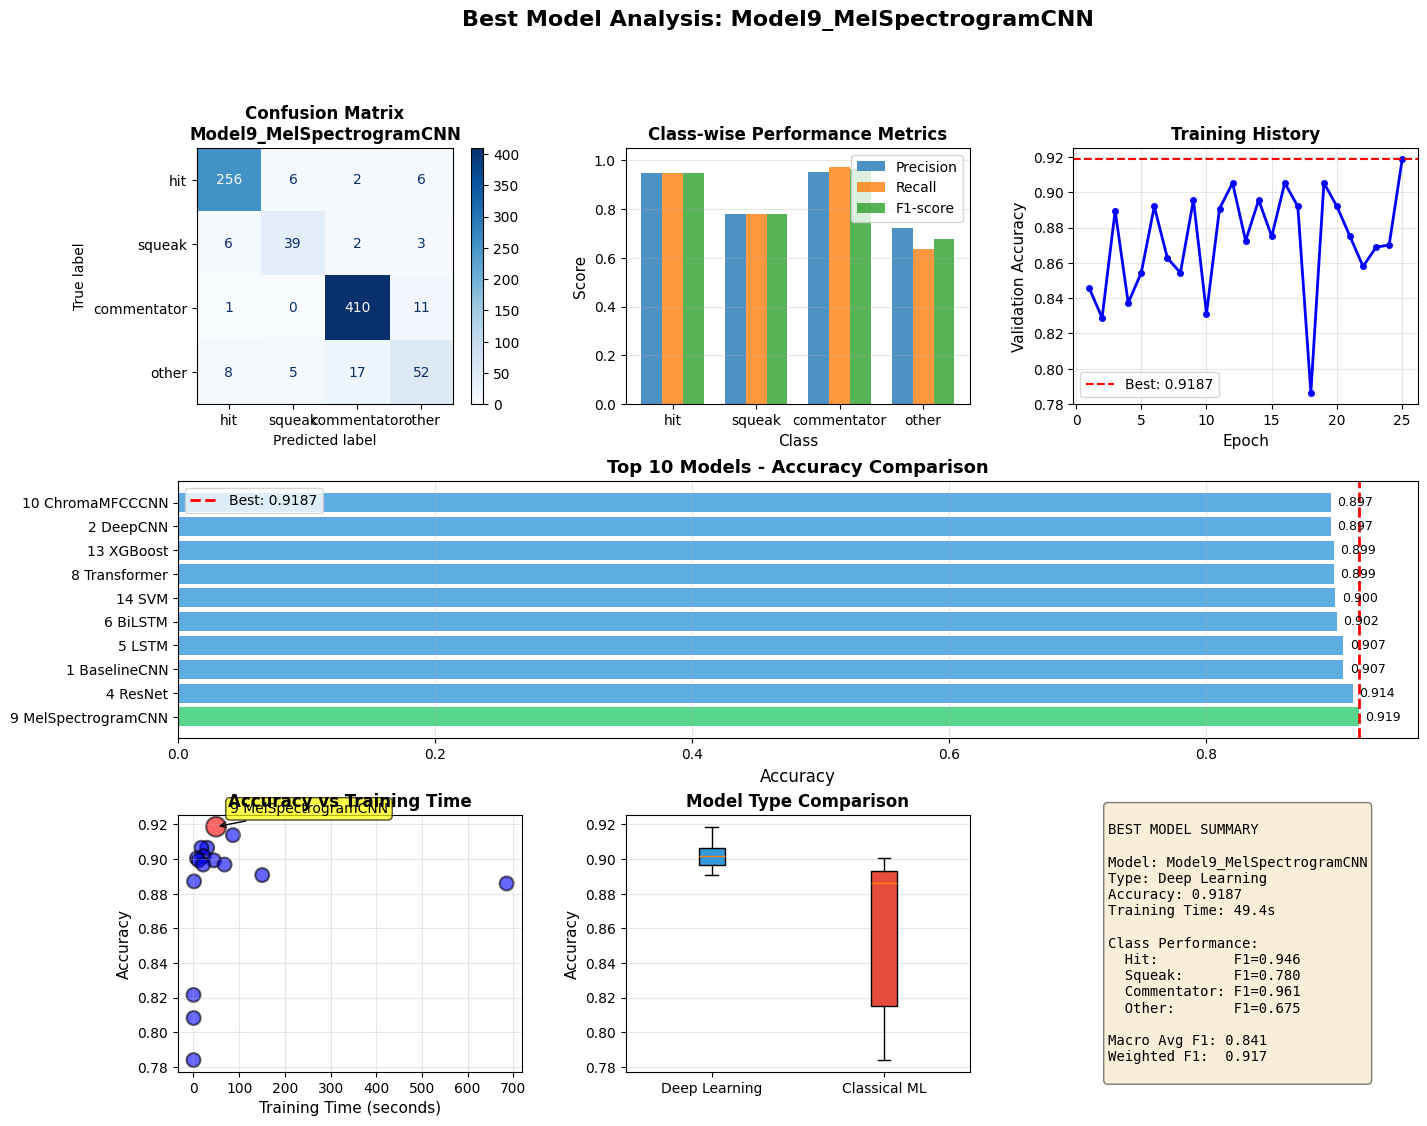


✓ Visualizations generated for best model: Model9_MelSpectrogramCNN


In [79]:
# Beautiful visualizations for the best model
if 'results' in globals() and results:
    valid_results = [(name, r) for name, r in results.items() if 'error' not in r]
    if valid_results:
        best_model_name, best_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        
        # Create comprehensive visualization
        fig = plt.figure(figsize=(16, 12))
        gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)
        
        # 1. Confusion Matrix
        ax1 = fig.add_subplot(gs[0, 0])
        from sklearn.metrics import confusion_matrix
        if 'model_type' in best_result and best_result['model_type'] == 'pytorch':
            # For PyTorch models, we need to get predictions
            model = best_result['model']
            model.eval()
            all_preds, all_truths = [], []
            
            # Try to use val_loaders if available, otherwise use direct data
            try:
                # Determine which loader to use based on model name
                if 'Mel' in best_model_name:
                    if 'val_loaders' in globals() and 'mel' in val_loaders:
                        loader = val_loaders['mel']
                    elif 'X_va_mel' in globals() and 'y_va' in globals():
                        # Create loader on the fly
                        loader = DataLoader(MelDataset(X_va_mel, y_va), batch_size=64)
                    else:
                        loader = None
                elif 'Chroma' in best_model_name:
                    if 'val_loaders' in globals() and 'chroma' in val_loaders:
                        loader = val_loaders['chroma']
                    elif 'X_va_chroma' in globals() and 'y_va' in globals():
                        # Create loader on the fly
                        loader = DataLoader(ChromaMFCCDataset(X_va_chroma, y_va), batch_size=64)
                    else:
                        loader = None
                else:
                    if 'val_loaders' in globals() and 'mfcc' in val_loaders:
                        loader = val_loaders['mfcc']
                    elif 'X_va' in globals() and 'y_va' in globals():
                        # Create loader on the fly
                        loader = DataLoader(MFCCset(X_va, y_va), batch_size=64)
                    else:
                        loader = None
                
                if loader is not None:
                    with torch.no_grad():
                        for xb, yb in loader:
                            xb = xb.to(device)
                            preds = model(xb).argmax(1).cpu().numpy()
                            all_preds.extend(preds)
                            all_truths.extend(yb)
                else:
                    # Fallback: reconstruct from validation data directly
                    print("Warning: Loader not available, generating predictions from validation data...")
                    if 'Mel' in best_model_name and 'X_va_mel' in globals():
                        for i, feat in enumerate(X_va_mel):
                            feat_tensor = torch.tensor(pad_mel(feat), dtype=torch.float32)[None].to(device)
                            with torch.no_grad():
                                pred = model(feat_tensor).argmax(1).cpu().numpy()[0]
                            all_preds.append(pred)
                            all_truths.append(y_va[i])
                    elif 'Chroma' in best_model_name and 'X_va_chroma' in globals():
                        for i, feat in enumerate(X_va_chroma):
                            feat_tensor = torch.tensor(pad_chroma_mfcc(feat), dtype=torch.float32)[None].to(device)
                            with torch.no_grad():
                                pred = model(feat_tensor).argmax(1).cpu().numpy()[0]
                            all_preds.append(pred)
                            all_truths.append(y_va[i])
                    elif 'X_va' in globals():
                        for i, feat in enumerate(X_va):
                            feat_tensor = torch.tensor(pad(feat), dtype=torch.float32)[None].to(device)
                            with torch.no_grad():
                                pred = model(feat_tensor).argmax(1).cpu().numpy()[0]
                            all_preds.append(pred)
                            all_truths.append(y_va[i])
            except Exception as e:
                print(f"Warning: Could not generate predictions: {e}")
                all_preds = []
                all_truths = []
        elif 'model' in best_result and 'model_type' in best_result and best_result['model_type'] == 'classical_ml':
            # For classical ML
            ml_model = best_result['model']
            scaler = best_result.get('scaler', None)
            X_val_scaled = scaler.transform(X_va_flat) if scaler else X_va_flat
            all_preds = ml_model.predict(X_val_scaled)
            all_truths = y_va_array
        else:
            # Fallback: try to reconstruct from report if available
            all_preds = []
            all_truths = []
        
        if len(all_preds) > 0 and len(all_truths) > 0:
            cm = confusion_matrix(all_truths, all_preds, labels=[0, 1, 2, 3])
            cm_display = ConfusionMatrixDisplay(cm, display_labels=["hit", "squeak", "commentator", "other"])
            cm_display.plot(ax=ax1, cmap='Blues', values_format='d')
            ax1.set_title(f'Confusion Matrix\n{best_model_name}', fontsize=12, fontweight='bold')
        else:
            ax1.text(0.5, 0.5, 'Confusion Matrix\nnot available\n(using report data)', 
                    ha='center', va='center', fontsize=12, transform=ax1.transAxes)
            ax1.set_title(f'Confusion Matrix\n{best_model_name}', fontsize=12, fontweight='bold')
        
        # 2. Class-wise Performance (F1, Precision, Recall)
        ax2 = fig.add_subplot(gs[0, 1])
        report = best_result['report']
        classes = ['hit', 'squeak', 'commentator', 'other']
        metrics = ['precision', 'recall', 'f1-score']
        x = np.arange(len(classes))
        width = 0.25
        
        for i, metric in enumerate(metrics):
            values = [report[cls][metric] for cls in classes]
            ax2.bar(x + i*width, values, width, label=metric.capitalize(), alpha=0.8)
        
        ax2.set_xlabel('Class', fontsize=11)
        ax2.set_ylabel('Score', fontsize=11)
        ax2.set_title('Class-wise Performance Metrics', fontsize=12, fontweight='bold')
        ax2.set_xticks(x + width)
        ax2.set_xticklabels(classes)
        ax2.legend()
        ax2.grid(axis='y', alpha=0.3)
        ax2.set_ylim([0, 1.05])
        
        # 3. Training History (if available)
        ax3 = fig.add_subplot(gs[0, 2])
        if 'val_accs' in best_result and len(best_result['val_accs']) > 1:
            epochs = range(1, len(best_result['val_accs']) + 1)
            ax3.plot(epochs, best_result['val_accs'], 'b-o', linewidth=2, markersize=4)
            ax3.axhline(y=best_result['best_acc'], color='r', linestyle='--', 
                       label=f'Best: {best_result["best_acc"]:.4f}')
            ax3.set_xlabel('Epoch', fontsize=11)
            ax3.set_ylabel('Validation Accuracy', fontsize=11)
            ax3.set_title('Training History', fontsize=12, fontweight='bold')
            ax3.legend()
            ax3.grid(alpha=0.3)
        else:
            ax3.text(0.5, 0.5, 'No training history\n(classical ML model)', 
                    ha='center', va='center', fontsize=12, transform=ax3.transAxes)
            ax3.set_title('Training History', fontsize=12, fontweight='bold')
        
        # 4. Model Comparison - Accuracy
        ax4 = fig.add_subplot(gs[1, :])
        all_models_sorted = sorted(valid_results, key=lambda x: x[1]['best_acc'], reverse=True)
        model_names = [name.replace('Model', '').replace('_', ' ') for name, _ in all_models_sorted[:10]]
        accuracies = [r['best_acc'] for _, r in all_models_sorted[:10]]
        colors = ['#2ecc71' if name == best_model_name.replace('Model', '').replace('_', ' ') 
                 else '#3498db' for name in model_names]
        
        bars = ax4.barh(model_names, accuracies, color=colors, alpha=0.8)
        ax4.axvline(x=best_result['best_acc'], color='red', linestyle='--', linewidth=2,
                   label=f'Best: {best_result["best_acc"]:.4f}')
        ax4.set_xlabel('Accuracy', fontsize=12)
        ax4.set_title('Top 10 Models - Accuracy Comparison', fontsize=13, fontweight='bold')
        ax4.legend()
        ax4.grid(axis='x', alpha=0.3)
        
        # Add value labels on bars
        for i, (bar, acc) in enumerate(zip(bars, accuracies)):
            ax4.text(acc + 0.005, i, f'{acc:.3f}', va='center', fontsize=9)
        
        # 5. Accuracy vs Training Time Scatter
        ax5 = fig.add_subplot(gs[2, 0])
        times = [r['train_time'] for _, r in all_models_sorted]
        accs = [r['best_acc'] for _, r in all_models_sorted]
        colors_scatter = ['red' if name == best_model_name else 'blue' 
                         for name, _ in all_models_sorted]
        sizes = [200 if name == best_model_name else 100 for name, _ in all_models_sorted]
        
        ax5.scatter(times, accs, c=colors_scatter, s=sizes, alpha=0.6, edgecolors='black', linewidth=1.5)
        ax5.set_xlabel('Training Time (seconds)', fontsize=11)
        ax5.set_ylabel('Accuracy', fontsize=11)
        ax5.set_title('Accuracy vs Training Time', fontsize=12, fontweight='bold')
        ax5.grid(alpha=0.3)
        
        # Annotate best model
        best_idx = next(i for i, (name, _) in enumerate(all_models_sorted) if name == best_model_name)
        ax5.annotate(best_model_name.replace('Model', '').replace('_', ' '), 
                    (times[best_idx], accs[best_idx]),
                    xytext=(10, 10), textcoords='offset points',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0'))
        
        # 6. Model Type Comparison
        ax6 = fig.add_subplot(gs[2, 1])
        dl_accs = [r['best_acc'] for name, r in valid_results 
                  if name.startswith('Model') and int(name.split('_')[0].replace('Model', '')) <= 10]
        ml_accs = [r['best_acc'] for name, r in valid_results 
                  if name.startswith('Model') and int(name.split('_')[0].replace('Model', '')) > 10]
        
        box_data = [dl_accs, ml_accs]
        bp = ax6.boxplot(box_data, labels=['Deep Learning', 'Classical ML'], patch_artist=True)
        bp['boxes'][0].set_facecolor('#3498db')
        bp['boxes'][1].set_facecolor('#e74c3c')
        ax6.set_ylabel('Accuracy', fontsize=11)
        ax6.set_title('Model Type Comparison', fontsize=12, fontweight='bold')
        ax6.grid(axis='y', alpha=0.3)
        
        # 7. Best Model Summary
        ax7 = fig.add_subplot(gs[2, 2])
        ax7.axis('off')
        summary_text = f"""
BEST MODEL SUMMARY

Model: {best_model_name}
Type: {'Deep Learning' if best_result.get('model_type') == 'pytorch' else 'Classical ML'}
Accuracy: {best_result['best_acc']:.4f}
Training Time: {best_result['train_time']:.1f}s

Class Performance:
  Hit:         F1={report['hit']['f1-score']:.3f}
  Squeak:      F1={report['squeak']['f1-score']:.3f}
  Commentator: F1={report['commentator']['f1-score']:.3f}
  Other:       F1={report['other']['f1-score']:.3f}

Macro Avg F1: {report['macro avg']['f1-score']:.3f}
Weighted F1:  {report['weighted avg']['f1-score']:.3f}
        """
        ax7.text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
                verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        plt.suptitle(f'Best Model Analysis: {best_model_name}', 
                    fontsize=16, fontweight='bold', y=0.995)
        plt.show()
        
        print(f"\n✓ Visualizations generated for best model: {best_model_name}")
    else:
        print("No valid results found for visualization.")
else:
    print("No results available. Please train models first.")

In [80]:
import pathlib as pl
import pickle

MODEL_DIR = pl.Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

# Save the best model from results
if 'results' in globals() and results:
    valid_results = [(name, r) for name, r in results.items() if 'error' not in r]
    if valid_results:
        best_model_name, best_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        print(f"Saving best model: {best_model_name} (Accuracy: {best_result['best_acc']:.4f})")
        
        # Check if model exists and determine type
        if 'model' in best_result:
            model_obj = best_result['model']
            
            # Check if it's a PyTorch model
            if isinstance(model_obj, nn.Module) or ('model_type' in best_result and best_result['model_type'] == 'pytorch'):
                # Save PyTorch model
                pytorch_model = model_obj
                torch.save(pytorch_model.state_dict(), MODEL_DIR / "acoustic_classifier.pth")
                print(f"PyTorch model saved to {MODEL_DIR / 'acoustic_classifier.pth'}")
                
                # Also save model metadata
                metadata = {
                    'model_name': best_model_name,
                    'model_type': 'pytorch',
                    'accuracy': best_result['best_acc'],
                    'preprocessing': 'mel' if 'Mel' in best_model_name else ('chroma' if 'Chroma' in best_model_name else 'mfcc')
                }
                with open(MODEL_DIR / "acoustic_classifier_metadata.pkl", 'wb') as f:
                    pickle.dump(metadata, f)
                    
            elif 'model_type' in best_result and best_result['model_type'] == 'classical_ml':
                # Save classical ML model
                ml_model = model_obj
                scaler = best_result.get('scaler', None)
                
                model_data = {
                    'model': ml_model,
                    'scaler': scaler,
                    'model_name': best_model_name,
                    'model_type': 'classical_ml',
                    'accuracy': best_result['best_acc']
                }
                
                with open(MODEL_DIR / "acoustic_classifier.pkl", 'wb') as f:
                    pickle.dump(model_data, f)
                print(f"Classical ML model saved to {MODEL_DIR / 'acoustic_classifier.pkl'}")
            else:
                # Try to infer type from model object
                if hasattr(model_obj, 'predict') or hasattr(model_obj, 'predict_proba'):
                    # Likely a sklearn model
                    ml_model = model_obj
                    scaler = best_result.get('scaler', None)
                    
                    model_data = {
                        'model': ml_model,
                        'scaler': scaler,
                        'model_name': best_model_name,
                        'model_type': 'classical_ml',
                        'accuracy': best_result['best_acc']
                    }
                    
                    with open(MODEL_DIR / "acoustic_classifier.pkl", 'wb') as f:
                        pickle.dump(model_data, f)
                    print(f"Classical ML model saved to {MODEL_DIR / 'acoustic_classifier.pkl'}")
                elif hasattr(model_obj, 'state_dict'):
                    # Likely a PyTorch model
                    torch.save(model_obj.state_dict(), MODEL_DIR / "acoustic_classifier.pth")
                    print(f"PyTorch model saved to {MODEL_DIR / 'acoustic_classifier.pth'}")
                else:
                    print(f"Unknown model type for {best_model_name}. Model object: {type(model_obj)}")
        else:
            print(f"Model not found in results for {best_model_name}. Cannot save.")
    else:
        print("No valid models found in results.")
else:
    # Fallback: try to save the baseline model if it exists
    if 'model' in globals() and isinstance(model, nn.Module):
        torch.save(model.state_dict(), MODEL_DIR / "acoustic_classifier.pth")
        print(f"Baseline PyTorch model saved to {MODEL_DIR / 'acoustic_classifier.pth'}")
    else:
        print("No model available to save. Please train models first.")


Saving best model: Model9_MelSpectrogramCNN (Accuracy: 0.9187)
PyTorch model saved to ..\models\acoustic_classifier.pth


Debug: Checking results...
  Model1_BaselineCNN: has_model=True, model_type=pytorch, model_is_nn=True
  Model2_DeepCNN: has_model=True, model_type=pytorch, model_is_nn=True
  Model3_WideCNN: has_model=True, model_type=pytorch, model_is_nn=True

Found 9 neural network models in results
Visualizing best neural network: Model9_MelSpectrogramCNN
Accuracy: 0.9187
Training time: 49.4s



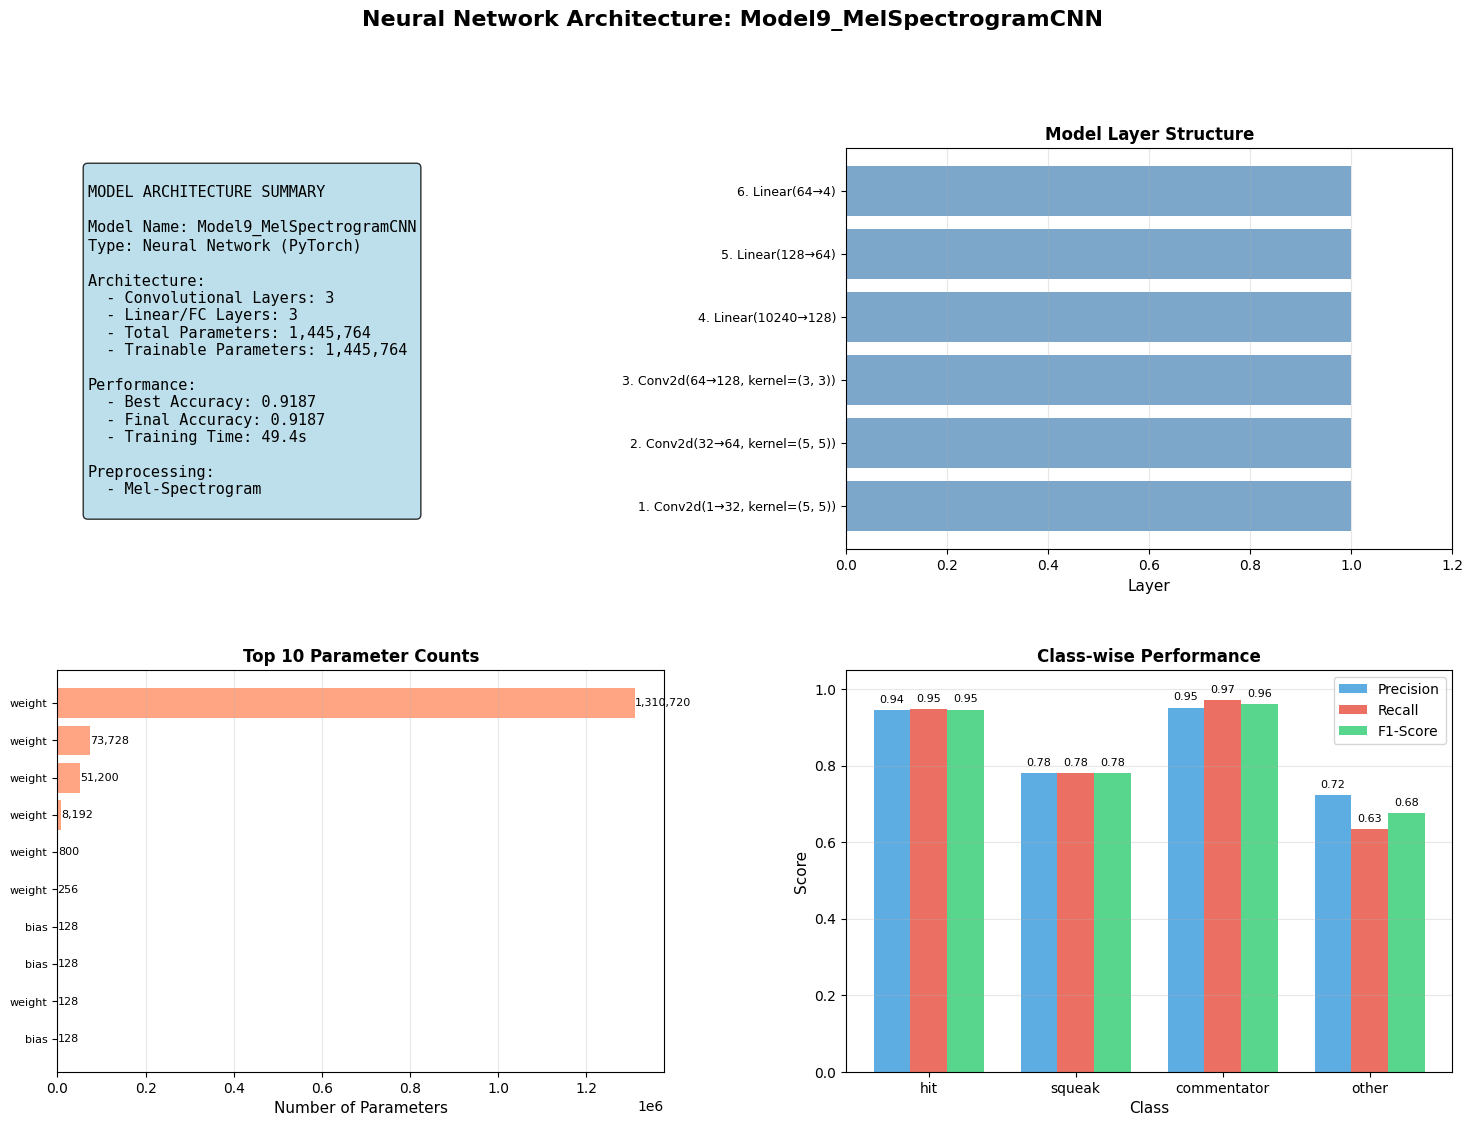


DETAILED MODEL STRUCTURE
Model9_MelSpectrogramCNN(
  (conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (5): ReLU()
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=10240, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128

In [ ]:
# Visualization of the best neural network architecture
if 'results' in globals() and results:
    # Debug: print what's in results
    print("Debug: Checking results...")
    for name, r in list(results.items())[:3]:  # Check first 3
        if 'error' not in r:
            print(f"  {name}: has_model={('model' in r)}, model_type={r.get('model_type', 'NOT SET')}, model_is_nn={('model' in r and isinstance(r.get('model'), nn.Module))}")
    
    # Find best PyTorch/neural network model
    valid_results = [(name, r) for name, r in results.items() 
                     if 'error' not in r and 
                     (r.get('model_type') == 'pytorch' or 
                      ('model' in r and isinstance(r.get('model'), nn.Module)))]
    
    print(f"\nFound {len(valid_results)} neural network models in results")
    
    if valid_results:
        # Get the best neural network model
        best_nn_name, best_nn_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        best_nn_model = best_nn_result['model']
        
        print(f"Visualizing best neural network: {best_nn_name}")
        print(f"Accuracy: {best_nn_result['best_acc']:.4f}")
        print(f"Training time: {best_nn_result['train_time']:.1f}s\n")
        
        # Create visualization
        fig = plt.figure(figsize=(18, 12))
        gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.3)
        
        # 1. Model Architecture Summary
        ax1 = fig.add_subplot(gs[0, 0])
        ax1.axis('off')
        
        # Get model structure
        model_str = str(best_nn_model)
        # Count layers
        conv_layers = sum(1 for name, module in best_nn_model.named_modules() 
                         if isinstance(module, (nn.Conv2d, nn.Conv1d)))
        linear_layers = sum(1 for name, module in best_nn_model.named_modules() 
                           if isinstance(module, nn.Linear))
        total_params = sum(p.numel() for p in best_nn_model.parameters())
        trainable_params = sum(p.numel() for p in best_nn_model.parameters() if p.requires_grad)
        
        summary_text = f"""
MODEL ARCHITECTURE SUMMARY

Model Name: {best_nn_name}
Type: Neural Network (PyTorch)

Architecture:
  - Convolutional Layers: {conv_layers}
  - Linear/FC Layers: {linear_layers}
  - Total Parameters: {total_params:,}
  - Trainable Parameters: {trainable_params:,}

Performance:
  - Best Accuracy: {best_nn_result['best_acc']:.4f}
  - Final Accuracy: {best_nn_result['final_acc']:.4f}
  - Training Time: {best_nn_result['train_time']:.1f}s

Preprocessing:
  - {'Mel-Spectrogram' if 'Mel' in best_nn_name else 'Chroma+MFCC' if 'Chroma' in best_nn_name else 'MFCC + Deltas'}
        """
        ax1.text(0.05, 0.95, summary_text, fontsize=11, family='monospace',
                verticalalignment='top', transform=ax1.transAxes,
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))
        
        # 2. Layer Structure Visualization
        ax2 = fig.add_subplot(gs[0, 1])
        
        # Extract layer information
        layers_info = []
        layer_names = []
        for name, module in best_nn_model.named_modules():
            if isinstance(module, (nn.Conv2d, nn.Conv1d, nn.Linear, nn.LSTM, nn.TransformerEncoder)):
                layer_names.append(name.split('.')[-1] if '.' in name else name)
                if isinstance(module, nn.Conv2d):
                    layers_info.append(f"Conv2d({module.in_channels}→{module.out_channels}, kernel={module.kernel_size})")
                elif isinstance(module, nn.Conv1d):
                    layers_info.append(f"Conv1d({module.in_channels}→{module.out_channels}, kernel={module.kernel_size})")
                elif isinstance(module, nn.Linear):
                    layers_info.append(f"Linear({module.in_features}→{module.out_features})")
                elif isinstance(module, nn.LSTM):
                    layers_info.append(f"LSTM(input={module.input_size}, hidden={module.hidden_size})")
                elif isinstance(module, nn.TransformerEncoder):
                    layers_info.append(f"TransformerEncoder(layers={len(module.layers)})")
        
        if layers_info:
            y_pos = np.arange(len(layers_info))
            ax2.barh(y_pos, [1]*len(layers_info), color='steelblue', alpha=0.7)
            ax2.set_yticks(y_pos)
            ax2.set_yticklabels([f"{i+1}. {info}" for i, info in enumerate(layers_info)], fontsize=9)
            ax2.set_xlabel('Layer', fontsize=11)
            ax2.set_title('Model Layer Structure', fontsize=12, fontweight='bold')
            ax2.set_xlim([0, 1.2])
            ax2.grid(axis='x', alpha=0.3)
        else:
            ax2.text(0.5, 0.5, 'Layer information\nnot available', 
                    ha='center', va='center', fontsize=12, transform=ax2.transAxes)
            ax2.set_title('Model Layer Structure', fontsize=12, fontweight='bold')
        
        # 3. Parameter Distribution
        ax3 = fig.add_subplot(gs[1, 0])
        
        param_counts = []
        param_names = []
        for name, param in best_nn_model.named_parameters():
            if param.requires_grad:
                param_counts.append(param.numel())
                # Shorten names
                short_name = name.split('.')[-1] if '.' in name else name
                param_names.append(short_name[:30])  # Limit length
        
        if param_counts:
            # Show top 10 parameters
            top_indices = np.argsort(param_counts)[-10:]
            top_counts = [param_counts[i] for i in top_indices]
            top_names = [param_names[i] for i in top_indices]
            
            ax3.barh(range(len(top_counts)), top_counts, color='coral', alpha=0.7)
            ax3.set_yticks(range(len(top_counts)))
            ax3.set_yticklabels(top_names, fontsize=8)
            ax3.set_xlabel('Number of Parameters', fontsize=11)
            ax3.set_title('Top 10 Parameter Counts', fontsize=12, fontweight='bold')
            ax3.grid(axis='x', alpha=0.3)
            
            # Add value labels
            for i, count in enumerate(top_counts):
                ax3.text(count, i, f'{count:,}', va='center', fontsize=8)
        else:
            ax3.text(0.5, 0.5, 'Parameter information\nnot available', 
                    ha='center', va='center', fontsize=12, transform=ax3.transAxes)
            ax3.set_title('Parameter Distribution', fontsize=12, fontweight='bold')
        
        # 4. Model Performance Metrics
        ax4 = fig.add_subplot(gs[1, 1])
        
        report = best_nn_result['report']
        classes = ['hit', 'squeak', 'commentator', 'other']
        metrics = {
            'Precision': [report[cls]['precision'] for cls in classes],
            'Recall': [report[cls]['recall'] for cls in classes],
            'F1-Score': [report[cls]['f1-score'] for cls in classes]
        }
        
        x = np.arange(len(classes))
        width = 0.25
        colors_metrics = ['#3498db', '#e74c3c', '#2ecc71']
        
        for i, (metric_name, values) in enumerate(metrics.items()):
            ax4.bar(x + i*width, values, width, label=metric_name, 
                   color=colors_metrics[i], alpha=0.8)
        
        ax4.set_xlabel('Class', fontsize=11)
        ax4.set_ylabel('Score', fontsize=11)
        ax4.set_title('Class-wise Performance', fontsize=12, fontweight='bold')
        ax4.set_xticks(x + width)
        ax4.set_xticklabels(classes)
        ax4.legend()
        ax4.grid(axis='y', alpha=0.3)
        ax4.set_ylim([0, 1.05])
        
        # Add value labels
        for i, (metric_name, values) in enumerate(metrics.items()):
            for j, val in enumerate(values):
                ax4.text(j + i*width, val + 0.02, f'{val:.2f}', 
                        ha='center', fontsize=8)
        
        plt.suptitle(f'Neural Network Architecture: {best_nn_name}', 
                    fontsize=16, fontweight='bold', y=0.995)
        plt.show()
        
        # Print detailed model structure
        print("\n" + "="*80)
        print("DETAILED MODEL STRUCTURE")
        print("="*80)
        print(best_nn_model)
        print("="*80)
        
    else:
        print("No neural network models found in results.")
else:
    print("No results available. Please train models first.")

Creating professional architecture diagram for: Model9_MelSpectrogramCNN



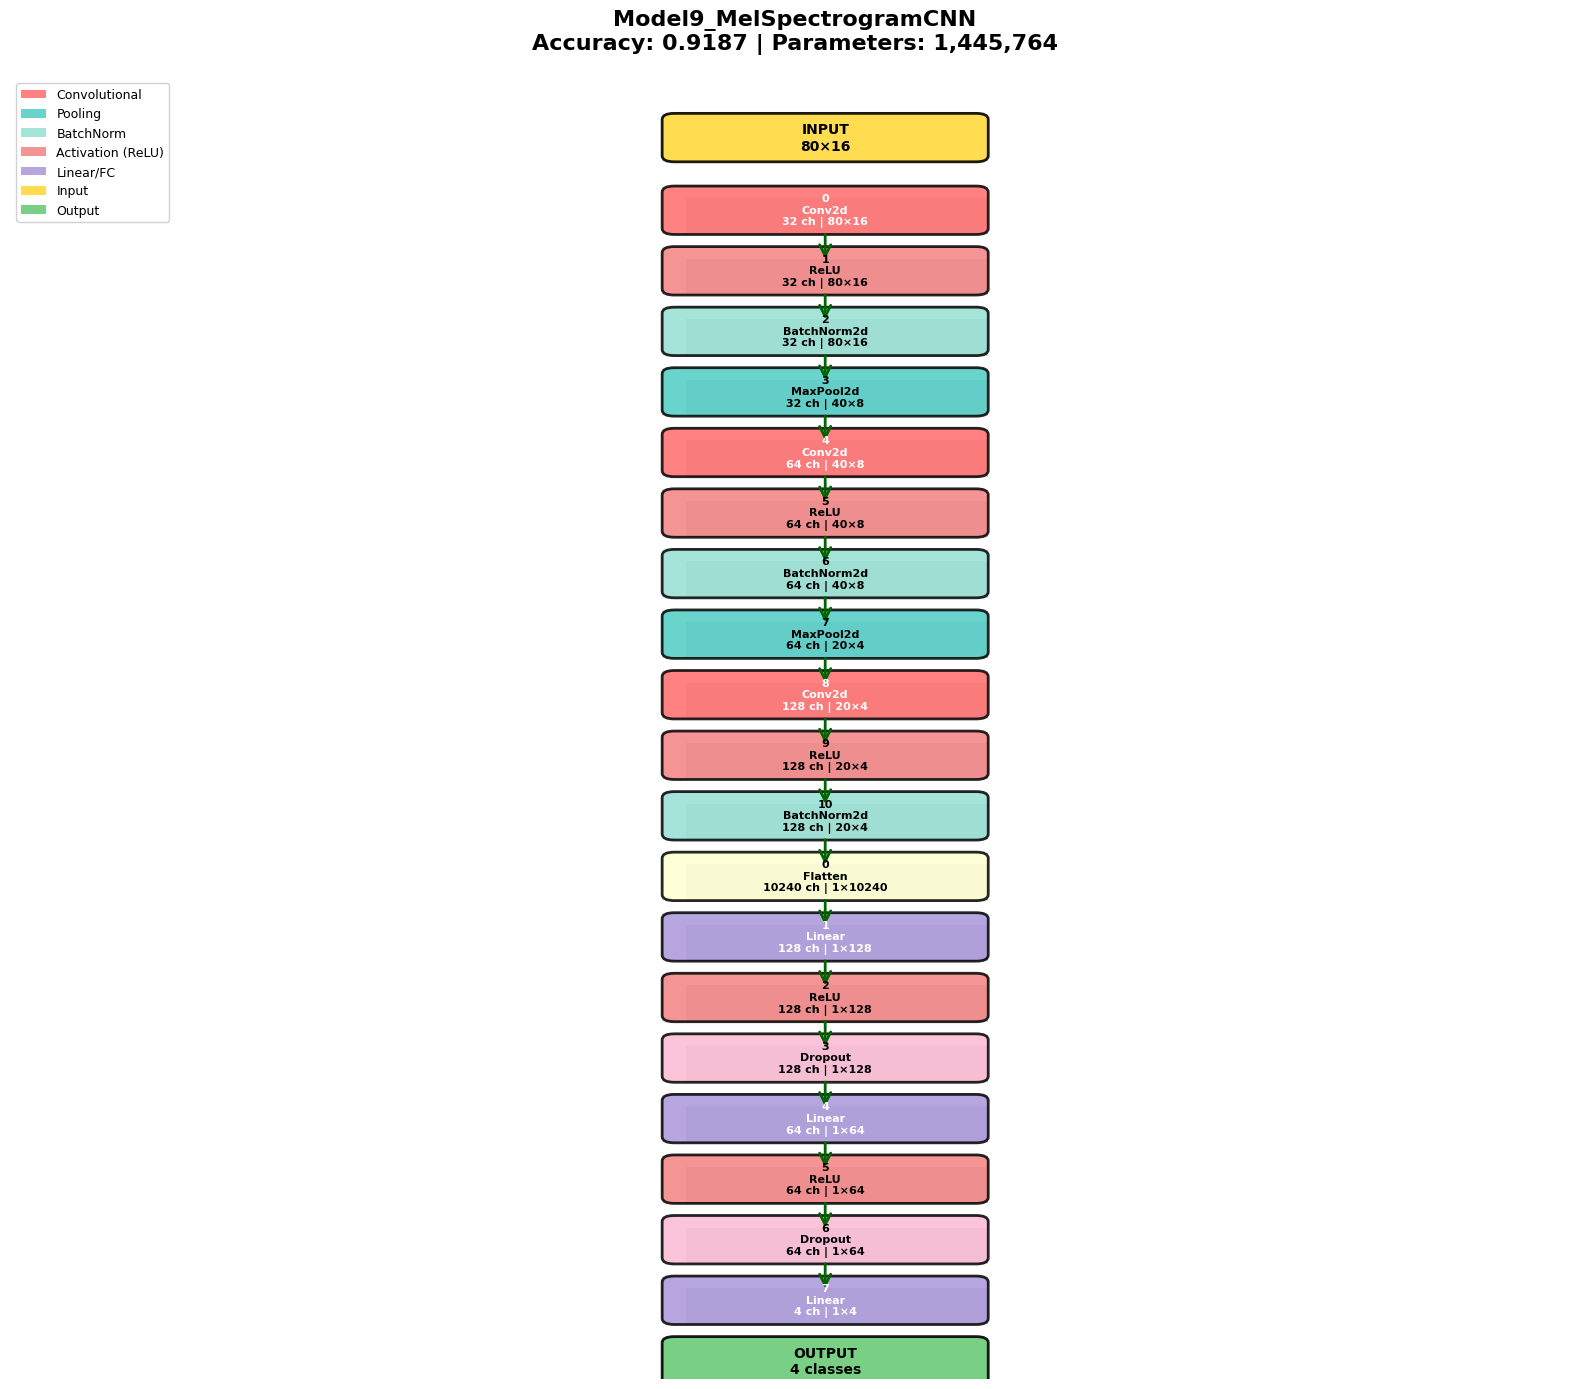

✓ Architecture visualization created for Model9_MelSpectrogramCNN


In [82]:
# Professional 3D-style architecture visualization (inspired by FCN diagrams)
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.patches import Rectangle
import matplotlib.patches as mpatches

if 'results' in globals() and results:
    # Find best PyTorch/neural network model
    valid_results = [(name, r) for name, r in results.items() 
                     if 'error' not in r and 
                     (r.get('model_type') == 'pytorch' or 
                      ('model' in r and isinstance(r.get('model'), nn.Module)))]
    
    if valid_results:
        best_nn_name, best_nn_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        best_nn_model = best_nn_result['model']
        
        print(f"Creating professional architecture diagram for: {best_nn_name}\n")
        
        # Extract layer information with shapes
        layers_info = []
        shapes = {}
        
        def hook(name):
            def fn(module, input, output):
                if isinstance(output, torch.Tensor):
                    shapes[name] = list(output.shape)
                elif isinstance(output, tuple):
                    shapes[name] = [list(o.shape) if isinstance(o, torch.Tensor) else str(o) for o in output]
            return fn
        
        hooks = []
        for name, module in best_nn_model.named_modules():
            if len(list(module.children())) == 0:  # Leaf module
                if isinstance(module, (nn.Conv2d, nn.Conv1d, nn.Linear, nn.LSTM, nn.TransformerEncoder, 
                                      nn.MaxPool2d, nn.AvgPool2d, nn.BatchNorm2d, nn.Dropout, 
                                      nn.ReLU, nn.Flatten, nn.AdaptiveAvgPool2d)):
                    layers_info.append((name, module))
                    hooks.append(module.register_forward_hook(hook(name)))
        
        # Create dummy input to get shapes
        try:
            if 'Mel' in best_nn_name:
                dummy_input = torch.randn(1, 1, 80, MAX_T)
            elif 'Chroma' in best_nn_name:
                dummy_input = torch.randn(1, 1, 25, MAX_T)
            else:
                dummy_input = torch.randn(1, 1, 75, MAX_T)
            
            with torch.no_grad():
                _ = best_nn_model(dummy_input)
        except Exception as e:
            print(f"Warning: Could not get shapes: {e}")
        
        for hook in hooks:
            hook.remove()
        
        # Group layers by type for better visualization
        conv_layers = []
        pool_layers = []
        norm_layers = []
        activation_layers = []
        linear_layers = []
        other_layers = []
        
        for name, module in layers_info:
            if isinstance(module, (nn.Conv2d, nn.Conv1d)):
                conv_layers.append((name, module))
            elif isinstance(module, (nn.MaxPool2d, nn.AvgPool2d, nn.AdaptiveAvgPool2d)):
                pool_layers.append((name, module))
            elif isinstance(module, (nn.BatchNorm2d,)):
                norm_layers.append((name, module))
            elif isinstance(module, (nn.ReLU,)):
                activation_layers.append((name, module))
            elif isinstance(module, (nn.Linear,)):
                linear_layers.append((name, module))
            else:
                other_layers.append((name, module))
        
        # Create figure
        fig = plt.figure(figsize=(16, 14))
        ax = fig.add_subplot(111)
        ax.set_xlim(-1, 12)
        ax.set_ylim(-0.5, len(layers_info) + 2)
        ax.axis('off')
        
        # Color scheme (inspired by FCN diagram)
        def get_layer_color(layer_type, module):
            if isinstance(module, (nn.Conv2d, nn.Conv1d)):
                return '#FF6B6B'  # Red/Orange for conv
            elif isinstance(module, (nn.MaxPool2d, nn.AvgPool2d, nn.AdaptiveAvgPool2d)):
                return '#4ECDC4'  # Teal for pooling
            elif isinstance(module, nn.BatchNorm2d):
                return '#95E1D3'  # Light teal for norm
            elif isinstance(module, nn.ReLU):
                return '#F38181'  # Light red for activation
            elif isinstance(module, nn.Linear):
                return '#AA96DA'  # Purple for linear
            elif isinstance(module, nn.Dropout):
                return '#FCBAD3'  # Pink for dropout
            elif isinstance(module, nn.Flatten):
                return '#FFFFD2'  # Yellow for flatten
            else:
                return '#C7CEEA'  # Light blue for other
        
        # Draw layers as 3D-looking blocks
        y_pos = len(layers_info) + 1
        block_width = 2.5
        block_height = 0.6
        
        # Draw INPUT
        input_shape = list(dummy_input.shape) if 'dummy_input' in locals() else [1, 1, 75, MAX_T]
        input_text = f"INPUT\n{input_shape[2]}×{input_shape[3]}"
        input_block = FancyBboxPatch((4.5, y_pos - block_height/2), block_width, block_height,
                                     boxstyle="round,pad=0.1", 
                                     facecolor='#FFD93D', edgecolor='black', linewidth=2, alpha=0.9)
        ax.add_patch(input_block)
        ax.text(5.75, y_pos, input_text, ha='center', va='center', fontsize=10, fontweight='bold')
        y_pos -= 1.2
        
        # Draw all layers
        for i, (name, module) in enumerate(layers_info):
            layer_type = type(module).__name__
            color = get_layer_color(layer_type, module)
            
            # Get shape info
            shape_str = ""
            if name in shapes:
                shape = shapes[name]
                if isinstance(shape, list) and len(shape) > 0:
                    if isinstance(shape[0], list):
                        s = shape[0]
                    else:
                        s = shape
                    if len(s) >= 2:
                        shape_str = f"{s[-2]}×{s[-1]}" if len(s) >= 2 else str(s)
            
            # Get channel/feature info
            channels = ""
            if isinstance(module, nn.Conv2d):
                channels = f"{module.out_channels}"
            elif isinstance(module, nn.Linear):
                channels = f"{module.out_features}"
            elif name in shapes:
                shape = shapes[name]
                if isinstance(shape, list) and len(shape) > 0:
                    if isinstance(shape[0], list):
                        s = shape[0]
                    else:
                        s = shape
                    if len(s) >= 1:
                        channels = f"{s[1]}" if len(s) > 1 else f"{s[0]}"
            
            # Short name
            short_name = name.split('.')[-1] if '.' in name else name
            if len(short_name) > 15:
                short_name = short_name[:12] + "..."
            
            # Draw 3D block with shadow effect
            # Shadow
            shadow = Rectangle((4.5 + 0.1, y_pos - block_height/2 - 0.1), 
                              block_width, block_height,
                              facecolor='gray', alpha=0.3, zorder=0)
            ax.add_patch(shadow)
            
            # Main block
            block = FancyBboxPatch((4.5, y_pos - block_height/2), block_width, block_height,
                                  boxstyle="round,pad=0.1", 
                                  facecolor=color, edgecolor='black', linewidth=2, alpha=0.85, zorder=1)
            ax.add_patch(block)
            
            # Layer text
            layer_text = f"{short_name}\n{layer_type}"
            if channels:
                layer_text += f"\n{channels} ch"
            if shape_str:
                layer_text += f" | {shape_str}"
            
            ax.text(5.75, y_pos, layer_text, ha='center', va='center', 
                   fontsize=8, fontweight='bold', color='white' if color in ['#FF6B6B', '#AA96DA'] else 'black')
            
            # Draw arrow
            if i < len(layers_info) - 1:
                arrow = FancyArrowPatch((5.75, y_pos - block_height/2 - 0.05), 
                                       (5.75, y_pos - block_height/2 - 0.55),
                                       arrowstyle='->', mutation_scale=20, 
                                       linewidth=2, color='darkgreen', zorder=2)
                ax.add_patch(arrow)
            
            y_pos -= 1.0
        
        # Draw OUTPUT
        output_text = "OUTPUT\n4 classes"
        output_block = FancyBboxPatch((4.5, y_pos - block_height/2), block_width, block_height,
                                     boxstyle="round,pad=0.1", 
                                     facecolor='#6BCB77', edgecolor='black', linewidth=2, alpha=0.9)
        ax.add_patch(output_block)
        ax.text(5.75, y_pos, output_text, ha='center', va='center', fontsize=10, fontweight='bold')
        
        # Title
        total_params = sum(p.numel() for p in best_nn_model.parameters())
        plt.title(f'{best_nn_name}\nAccuracy: {best_nn_result["best_acc"]:.4f} | Parameters: {total_params:,}',
                 fontsize=16, fontweight='bold', pad=20)
        
        # Legend
        legend_elements = [
            mpatches.Patch(facecolor='#FF6B6B', label='Convolutional', alpha=0.85),
            mpatches.Patch(facecolor='#4ECDC4', label='Pooling', alpha=0.85),
            mpatches.Patch(facecolor='#95E1D3', label='BatchNorm', alpha=0.85),
            mpatches.Patch(facecolor='#F38181', label='Activation (ReLU)', alpha=0.85),
            mpatches.Patch(facecolor='#AA96DA', label='Linear/FC', alpha=0.85),
            mpatches.Patch(facecolor='#FFD93D', label='Input', alpha=0.9),
            mpatches.Patch(facecolor='#6BCB77', label='Output', alpha=0.9),
        ]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=9, framealpha=0.9)
        
        plt.tight_layout()
        plt.show()
        
        print(f"✓ Architecture visualization created for {best_nn_name}")
        
    else:
        print("No neural network models found in results.")
else:
    print("No results available. Please train models first.")

In [83]:
# Generate detailed prompt for visualization agent
if 'results' in globals() and results:
    # Find best PyTorch/neural network model
    valid_results = [(name, r) for name, r in results.items() 
                     if 'error' not in r and 
                     (r.get('model_type') == 'pytorch' or 
                      ('model' in r and isinstance(r.get('model'), nn.Module)))]
    
    if valid_results:
        best_nn_name, best_nn_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        best_nn_model = best_nn_result['model']
        
        # Extract complete architecture information
        layers_detailed = []
        shapes = {}
        
        def hook(name):
            def fn(module, input, output):
                if isinstance(output, torch.Tensor):
                    shapes[name] = list(output.shape)
                elif isinstance(output, tuple):
                    shapes[name] = [list(o.shape) if isinstance(o, torch.Tensor) else str(o) for o in output]
            return fn
        
        hooks = []
        for name, module in best_nn_model.named_modules():
            if len(list(module.children())) == 0:  # Leaf module
                if isinstance(module, (nn.Conv2d, nn.Conv1d, nn.Linear, nn.LSTM, nn.TransformerEncoder, 
                                      nn.MaxPool2d, nn.AvgPool2d, nn.BatchNorm2d, nn.Dropout, 
                                      nn.ReLU, nn.Flatten, nn.AdaptiveAvgPool2d)):
                    layer_info = {
                        'name': name,
                        'type': type(module).__name__,
                        'module': module
                    }
                    
                    # Extract parameters based on layer type
                    if isinstance(module, nn.Conv2d):
                        layer_info['params'] = {
                            'in_channels': module.in_channels,
                            'out_channels': module.out_channels,
                            'kernel_size': module.kernel_size,
                            'stride': module.stride,
                            'padding': module.padding,
                            'bias': module.bias is not None
                        }
                    elif isinstance(module, nn.Conv1d):
                        layer_info['params'] = {
                            'in_channels': module.in_channels,
                            'out_channels': module.out_channels,
                            'kernel_size': module.kernel_size,
                            'stride': module.stride,
                            'padding': module.padding,
                            'bias': module.bias is not None
                        }
                    elif isinstance(module, nn.Linear):
                        layer_info['params'] = {
                            'in_features': module.in_features,
                            'out_features': module.out_features,
                            'bias': module.bias is not None
                        }
                    elif isinstance(module, nn.LSTM):
                        layer_info['params'] = {
                            'input_size': module.input_size,
                            'hidden_size': module.hidden_size,
                            'num_layers': module.num_layers,
                            'bidirectional': module.bidirectional,
                            'dropout': module.dropout
                        }
                    elif isinstance(module, (nn.MaxPool2d, nn.AvgPool2d)):
                        layer_info['params'] = {
                            'kernel_size': module.kernel_size,
                            'stride': module.stride if hasattr(module, 'stride') else None,
                            'padding': module.padding if hasattr(module, 'padding') else 0
                        }
                    elif isinstance(module, nn.BatchNorm2d):
                        layer_info['params'] = {
                            'num_features': module.num_features
                        }
                    elif isinstance(module, nn.Dropout):
                        layer_info['params'] = {
                            'p': module.p
                        }
                    else:
                        layer_info['params'] = {}
                    
                    layers_detailed.append(layer_info)
                    hooks.append(module.register_forward_hook(hook(name)))
        
        # Get input shape
        if 'Mel' in best_nn_name:
            input_shape = [1, 1, 80, MAX_T]
            input_description = "Mel-spectrogram (80 mel bins × 16 time frames)"
        elif 'Chroma' in best_nn_name:
            input_shape = [1, 1, 25, MAX_T]
            input_description = "Chroma + MFCC features (25 features × 16 time frames)"
        else:
            input_shape = [1, 1, 75, MAX_T]
            input_description = "MFCC + deltas (75 features × 16 time frames)"
        
        # Run forward pass to get shapes
        try:
            dummy_input = torch.randn(*input_shape)
            with torch.no_grad():
                _ = best_nn_model(dummy_input)
        except Exception as e:
            print(f"Warning: Could not get shapes: {e}")
        
        for hook in hooks:
            hook.remove()
        
        # Add shape information to layers
        for layer in layers_detailed:
            if layer['name'] in shapes:
                layer['output_shape'] = shapes[layer['name']]
        
        # Calculate total parameters
        total_params = sum(p.numel() for p in best_nn_model.parameters())
        trainable_params = sum(p.numel() for p in best_nn_model.parameters() if p.requires_grad)
        
        # Generate comprehensive prompt
        prompt = f"""
# Neural Network Architecture Visualization Request

## Model Information
- **Model Name**: {best_nn_name}
- **Model Type**: PyTorch Neural Network
- **Task**: Audio Classification (4 classes: hit, squeak, commentator, other)
- **Best Accuracy**: {best_nn_result['best_acc']:.4f}
- **Final Accuracy**: {best_nn_result['final_acc']:.4f}
- **Training Time**: {best_nn_result['train_time']:.1f} seconds
- **Total Parameters**: {total_params:,}
- **Trainable Parameters**: {trainable_params:,}

## Input Specification
- **Input Shape**: {input_shape}
- **Input Description**: {input_description}
- **Input Format**: 2D feature map (frequency × time)

## Output Specification
- **Output Shape**: [batch_size, 4]
- **Output Classes**: 4 (hit, squeak, commentator, other)
- **Output Type**: Classification logits

## Architecture Details

### Layer-by-Layer Structure:
"""
        
        for i, layer in enumerate(layers_detailed, 1):
            prompt += f"\n**Layer {i}: {layer['name']}**\n"
            prompt += f"- Type: {layer['type']}\n"
            
            if 'output_shape' in layer:
                shape = layer['output_shape']
                if isinstance(shape, list) and len(shape) > 0:
                    if isinstance(shape[0], list):
                        shape_str = str(shape[0])
                    else:
                        shape_str = str(shape)
                    prompt += f"- Output Shape: {shape_str}\n"
            
            if layer['params']:
                prompt += f"- Parameters:\n"
                for key, value in layer['params'].items():
                    if value is not None:
                        prompt += f"  - {key}: {value}\n"
        
        prompt += f"""
## Visualization Requirements

Please create a professional architecture diagram similar to FCN (Fully Convolutional Network) style visualization with:

1. **3D-looking blocks** with shadows for depth effect
2. **Color coding**:
   - Red/Orange (#FF6B6B) for Convolutional layers
   - Teal (#4ECDC4) for Pooling layers
   - Light Teal (#95E1D3) for BatchNorm layers
   - Light Red (#F38181) for Activation (ReLU) layers
   - Purple (#AA96DA) for Linear/FC layers
   - Pink (#FCBAD3) for Dropout layers
   - Yellow (#FFFFD2) for Flatten layers
   - Yellow (#FFD93D) for Input
   - Green (#6BCB77) for Output

3. **Layer Information Display**:
   - Layer name
   - Layer type
   - Number of channels/features
   - Output shape (if available)

4. **Flow Visualization**:
   - Vertical flow from top (input) to bottom (output)
   - Arrows connecting layers
   - Clear data flow direction

5. **Additional Elements**:
   - Title with model name and accuracy
   - Legend explaining color coding
   - Professional styling with rounded corners

## Performance Metrics by Class:
"""
        
        report = best_nn_result['report']
        for cls in ['hit', 'squeak', 'commentator', 'other']:
            if cls in report:
                prompt += f"- **{cls}**: Precision={report[cls]['precision']:.3f}, Recall={report[cls]['recall']:.3f}, F1={report[cls]['f1-score']:.3f}\n"
        
        prompt += f"""
## Model Summary String:
{str(best_nn_model)}

---
Please create a beautiful, professional visualization of this neural network architecture.
"""
        
        print("="*100)
        print("PROMPT FOR VISUALIZATION AGENT")
        print("="*100)
        print(prompt)
        print("="*100)
        
        # Save prompt to file
        prompt_file = pl.Path("../visualization_prompt.md")
        with open(prompt_file, 'w', encoding='utf-8') as f:
            f.write(prompt)
        
        print(f"\n✓ Prompt saved to: {prompt_file}")
        print("="*100)
        print("COPY THE PROMPT ABOVE OR USE THE SAVED FILE FOR YOUR VISUALIZATION AGENT")
        print("="*100)
        
    else:
        print("No neural network models found in results.")
else:
    print("No results available. Please train models first.")

PROMPT FOR VISUALIZATION AGENT

# Neural Network Architecture Visualization Request

## Model Information
- **Model Name**: Model9_MelSpectrogramCNN
- **Model Type**: PyTorch Neural Network
- **Task**: Audio Classification (4 classes: hit, squeak, commentator, other)
- **Best Accuracy**: 0.9187
- **Final Accuracy**: 0.9187
- **Training Time**: 49.4 seconds
- **Total Parameters**: 1,445,764
- **Trainable Parameters**: 1,445,764

## Input Specification
- **Input Shape**: [1, 1, 80, 16]
- **Input Description**: Mel-spectrogram (80 mel bins × 16 time frames)
- **Input Format**: 2D feature map (frequency × time)

## Output Specification
- **Output Shape**: [batch_size, 4]
- **Output Classes**: 4 (hit, squeak, commentator, other)
- **Output Type**: Classification logits

## Architecture Details

### Layer-by-Layer Structure:

**Layer 1: conv.0**
- Type: Conv2d
- Output Shape: [1, 32, 80, 16]
- Parameters:
  - in_channels: 1
  - out_channels: 32
  - kernel_size: (5, 5)
  - stride: (1, 1)
  - 

In [84]:
# Generate concise model list for PowerPoint slide
if 'results' in globals() and results:
    valid_results = [(name, r) for name, r in results.items() if 'error' not in r]
    
    if valid_results:
        # Separate DL and ML models
        dl_models = []
        ml_models = []
        
        for name, result in valid_results:
            model_type = result.get('model_type', 'unknown')
            if model_type == 'pytorch' or ('model' in result and isinstance(result.get('model'), nn.Module)):
                dl_models.append((name, result))
            elif model_type == 'classical_ml':
                ml_models.append((name, result))
            else:
                # Try to infer
                if 'model' in result and isinstance(result.get('model'), nn.Module):
                    dl_models.append((name, result))
                else:
                    ml_models.append((name, result))
        
        # Sort by accuracy
        dl_models.sort(key=lambda x: x[1]['best_acc'], reverse=True)
        ml_models.sort(key=lambda x: x[1]['best_acc'], reverse=True)
        
        print("="*80)
        print("MODELS TESTED - FOR POWERPOINT SLIDE")
        print("="*80)
        print()
        
        print("DEEP LEARNING MODELS (10 models):")
        print("-" * 80)
        for i, (name, result) in enumerate(dl_models, 1):
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            time = result['train_time']
            print(f"{i:2d}. {model_short:30s} | Acc: {acc:.3f} | Time: {time:.1f}s")
        
        print()
        print("CLASSICAL ML MODELS (7 models):")
        print("-" * 80)
        for i, (name, result) in enumerate(ml_models, 1):
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            time = result['train_time']
            print(f"{i:2d}. {model_short:30s} | Acc: {acc:.3f} | Time: {time:.1f}s")
        
        print()
        print("="*80)
        print("TOP 5 MODELS:")
        print("="*80)
        all_sorted = sorted(valid_results, key=lambda x: x[1]['best_acc'], reverse=True)
        for i, (name, result) in enumerate(all_sorted[:5], 1):
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            model_type = "DL" if name in [n for n, _ in dl_models] else "ML"
            print(f"{i}. {model_short:30s} | {model_type:2s} | Acc: {acc:.3f}")
        
        print()
        print("="*80)
        print("FORMATTED FOR PPTX (copy below):")
        print("="*80)
        print()
        
        # Very concise format for PowerPoint
        print("📊 MODELS TESTED (17 total)")
        print()
        print("Deep Learning (10):")
        for name, result in dl_models:
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            print(f"  • {model_short:25s} {acc:.1%}")
        
        print()
        print("Classical ML (7):")
        for name, result in ml_models:
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            print(f"  • {model_short:25s} {acc:.1%}")
        
        print()
        print("="*80)
        print("VERY SHORT VERSION FOR PPTX:")
        print("="*80)
        print()
        
        # Ultra-short version
        print("Deep Learning:")
        for name, result in dl_models:
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            print(f"• {model_short} - {acc:.1%}")
        
        print()
        print("Classical ML:")
        for name, result in ml_models:
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            print(f"• {model_short} - {acc:.1%}")
        
        print()
        best_name, best_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        best_short = best_name.replace('Model', '').replace('_', ' ')
        print(f"🏆 Best: {best_short} ({best_result['best_acc']:.1%})")
        
        print()
        print("="*80)
        print("TABLE FORMAT (for PowerPoint table):")
        print("="*80)
        print()
        print("Model Name | Type | Accuracy | Time (s)")
        print("-" * 60)
        for name, result in all_sorted:
            model_short = name.replace('Model', '').replace('_', ' ')
            acc = result['best_acc']
            time = result['train_time']
            model_type = "DL" if name in [n for n, _ in dl_models] else "ML"
            print(f"{model_short:30s} | {model_type:4s} | {acc:.3f} | {time:.1f}")
        
    else:
        print("No valid results found.")
else:
    print("No results available. Please train models first.")

MODELS TESTED - FOR POWERPOINT SLIDE

DEEP LEARNING MODELS (10 models):
--------------------------------------------------------------------------------
 1. 9 MelSpectrogramCNN            | Acc: 0.919 | Time: 49.4s
 2. 4 ResNet                       | Acc: 0.914 | Time: 86.4s
 3. 1 BaselineCNN                  | Acc: 0.907 | Time: 29.9s
 4. 5 LSTM                         | Acc: 0.907 | Time: 17.3s
 5. 6 BiLSTM                       | Acc: 0.902 | Time: 22.4s
 6. 8 Transformer                  | Acc: 0.899 | Time: 44.8s
 7. 2 DeepCNN                      | Acc: 0.897 | Time: 67.9s
 8. 10 ChromaMFCCCNN               | Acc: 0.897 | Time: 21.2s
 9. 3 WideCNN                      | Acc: 0.891 | Time: 150.4s

CLASSICAL ML MODELS (7 models):
--------------------------------------------------------------------------------
 1. 14 SVM                         | Acc: 0.900 | Time: 7.5s
 2. 13 XGBoost                     | Acc: 0.899 | Time: 11.4s
 3. 11 RandomForest                | Acc: 0.887 | T

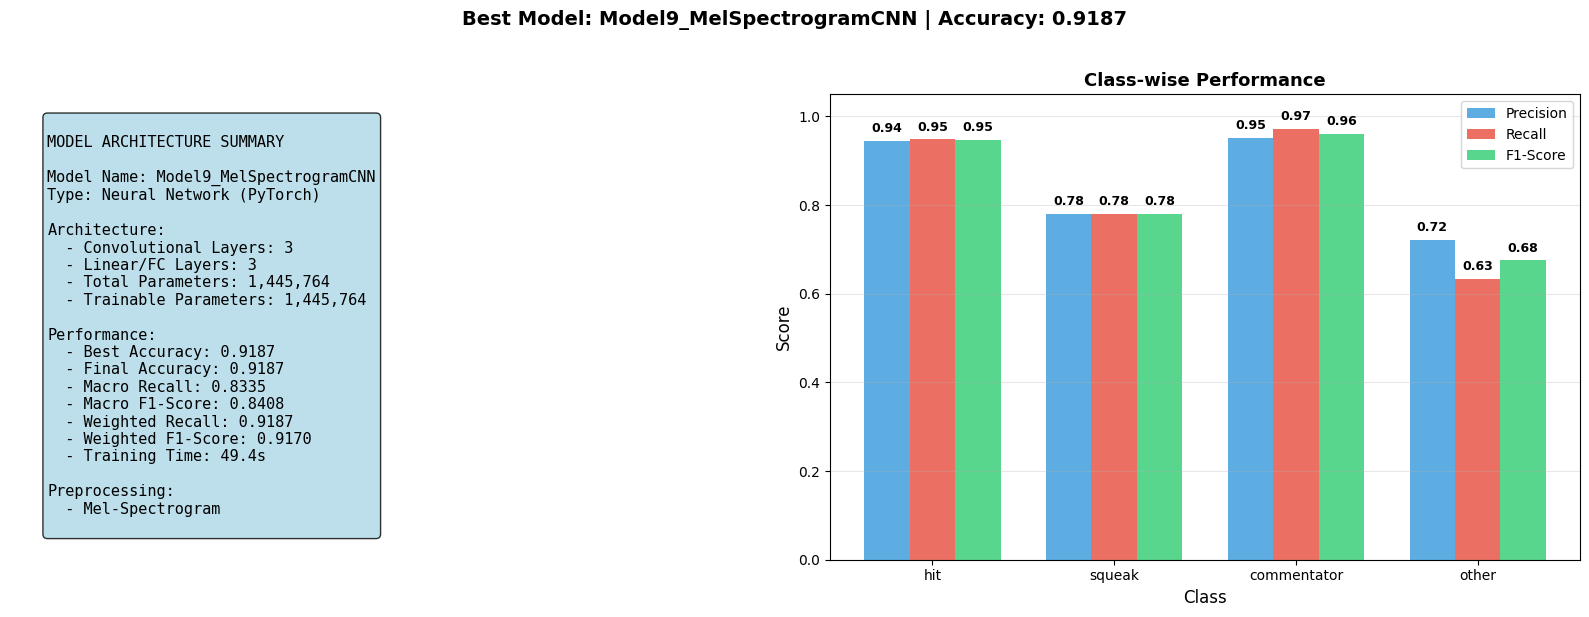

In [85]:
# Simplified visualization: Architecture Summary + Class Performance
if 'results' in globals() and results:
    # Find best PyTorch/neural network model
    valid_results = [(name, r) for name, r in results.items() 
                     if 'error' not in r and 
                     (r.get('model_type') == 'pytorch' or 
                      ('model' in r and isinstance(r.get('model'), nn.Module)))]
    
    if valid_results:
        best_nn_name, best_nn_result = max(valid_results, key=lambda x: x[1]['best_acc'])
        best_nn_model = best_nn_result['model']
        
        # Create visualization with only 2 plots
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        
        # 1. Model Architecture Summary
        ax1 = axes[0]
        ax1.axis('off')
        
        # Get model structure
        conv_layers = sum(1 for name, module in best_nn_model.named_modules() 
                         if isinstance(module, (nn.Conv2d, nn.Conv1d)))
        linear_layers = sum(1 for name, module in best_nn_model.named_modules() 
                           if isinstance(module, nn.Linear))
        total_params = sum(p.numel() for p in best_nn_model.parameters())
        trainable_params = sum(p.numel() for p in best_nn_model.parameters() if p.requires_grad)
        
        # Get overall metrics from report
        report = best_nn_result['report']
        macro_recall = report.get('macro avg', {}).get('recall', 0.0)
        macro_f1 = report.get('macro avg', {}).get('f1-score', 0.0)
        weighted_recall = report.get('weighted avg', {}).get('recall', 0.0)
        weighted_f1 = report.get('weighted avg', {}).get('f1-score', 0.0)
        
        summary_text = f"""
MODEL ARCHITECTURE SUMMARY

Model Name: {best_nn_name}
Type: Neural Network (PyTorch)

Architecture:
  - Convolutional Layers: {conv_layers}
  - Linear/FC Layers: {linear_layers}
  - Total Parameters: {total_params:,}
  - Trainable Parameters: {trainable_params:,}

Performance:
  - Best Accuracy: {best_nn_result['best_acc']:.4f}
  - Final Accuracy: {best_nn_result['final_acc']:.4f}
  - Macro Recall: {macro_recall:.4f}
  - Macro F1-Score: {macro_f1:.4f}
  - Weighted Recall: {weighted_recall:.4f}
  - Weighted F1-Score: {weighted_f1:.4f}
  - Training Time: {best_nn_result['train_time']:.1f}s

Preprocessing:
  - {'Mel-Spectrogram' if 'Mel' in best_nn_name else 'Chroma+MFCC' if 'Chroma' in best_nn_name else 'MFCC + Deltas'}
        """
        ax1.text(0.05, 0.95, summary_text, fontsize=11, family='monospace',
                verticalalignment='top', transform=ax1.transAxes,
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))
        
        # 2. Model Performance Metrics
        ax2 = axes[1]
        
        report = best_nn_result['report']
        classes = ['hit', 'squeak', 'commentator', 'other']
        metrics = {
            'Precision': [report[cls]['precision'] for cls in classes],
            'Recall': [report[cls]['recall'] for cls in classes],
            'F1-Score': [report[cls]['f1-score'] for cls in classes]
        }
        
        x = np.arange(len(classes))
        width = 0.25
        colors_metrics = ['#3498db', '#e74c3c', '#2ecc71']
        
        for i, (metric_name, values) in enumerate(metrics.items()):
            ax2.bar(x + i*width, values, width, label=metric_name, 
                   color=colors_metrics[i], alpha=0.8)
        
        ax2.set_xlabel('Class', fontsize=12)
        ax2.set_ylabel('Score', fontsize=12)
        ax2.set_title('Class-wise Performance', fontsize=13, fontweight='bold')
        ax2.set_xticks(x + width)
        ax2.set_xticklabels(classes)
        ax2.legend(fontsize=10)
        ax2.grid(axis='y', alpha=0.3)
        ax2.set_ylim([0, 1.05])
        
        # Add value labels
        for i, (metric_name, values) in enumerate(metrics.items()):
            for j, val in enumerate(values):
                ax2.text(j + i*width, val + 0.02, f'{val:.2f}', 
                        ha='center', fontsize=9, fontweight='bold')
        
        plt.suptitle(f'Best Model: {best_nn_name} | Accuracy: {best_nn_result["best_acc"]:.4f}', 
                    fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.show()
        
    else:
        print("No neural network models found in results.")
else:
    print("No results available. Please train models first.")